# EXPLORATORY DATA ANALYSIS LAB — BCSE331P
**Name:** Adharsh  
**Reg. No:** 23BDS0029

**Github Link:** https://github.com/CoderAD4/EDA-Lab

**Video Link:** https://drive.google.com/file/d/1UVMAhRBpkWotaKH2lMnisyNivjbSAMDt/view?usp=sharing

Compiled Python code for Assessments I, II, III, V, VI, VII, VIII and IX.  
Dataset used in assessments: `GSS7402.xlsx` (place it in the working directory, or edit `data_path` below).

In [ ]:
import importlib, subprocess, sys
for pkg, mod in [("pandas","pandas"),("numpy","numpy"),("matplotlib","matplotlib"),("seaborn","seaborn"),
                 ("scipy","scipy"),("scikit-learn","sklearn"),("statsmodels","statsmodels"),("openpyxl","openpyxl")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, math, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", 50)

for _p in ["/GSS7402.xlsx", "/content/GSS7402.xlsx", "GSS7402.xlsx"]:
    if os.path.exists(_p):
        data_path = _p
        break
else:
    raise FileNotFoundError("GSS7402.xlsx not found - upload it or edit data_path.")
print("Using dataset:", data_path)


def scale(df):
    """Equivalent of R's scale(): centre and divide by the sample SD (n-1)."""
    return (df - df.mean()) / df.std(ddof=1)


def get_mode(s):
    """Most frequent non-missing value (equivalent of the R get_mode helper)."""
    s = s.dropna()
    return s.value_counts().idxmax()


def skewness(x):
    """e1071::skewness (type 3, the R default)."""
    x = np.asarray(pd.Series(x).dropna(), dtype=float)
    n = len(x)
    m2 = np.mean((x - x.mean()) ** 2)
    m3 = np.mean((x - x.mean()) ** 3)
    return (m3 / m2 ** 1.5) * ((n - 1) / n) ** 1.5


def kurtosis(x):
    """e1071::kurtosis (type 3, excess kurtosis, the R default)."""
    x = np.asarray(pd.Series(x).dropna(), dtype=float)
    n = len(x)
    m2 = np.mean((x - x.mean()) ** 2)
    m4 = np.mean((x - x.mean()) ** 4)
    return (m4 / m2 ** 2) * ((n - 1) / n) ** 2 - 3

Using dataset: GSS7402.xlsx


---
# ASSESSMENT I — Merging and Data Transformation
## Part 1: Merging / Concatenating data frames

In [ ]:
dataframe1 = pd.DataFrame({
    "ProductID": range(101, 111),
    "NameofProd": ["Laptop", "Mouse", "Keyboard", "Monitor", "Printer",
                   "Webcam", "Speaker", "Headset", "Router", "Tablet"],
    "Price": [55000, 800, 1500, 9500, 6500, 2200, 3000, 2500, 1800, 21000],
})
dataframe2 = pd.DataFrame({
    "ProductID": range(105, 115),
    "Company_Location": ["Chennai", "Bangalore", "Mumbai", "Delhi", "Pune",
                         "Hyderabad", "Kolkata", "Ahmedabad", "Jaipur", "Kochi"],
})
dataframe3 = pd.DataFrame({
    "ProductID": range(201, 211),
    "NameofProd": ["Charger", "PowerBank", "SSD", "HDD", "GraphicsCard",
                   "RAM", "Motherboard", "SmartWatch", "Earbuds", "Drone"],
    "Price": [1200, 2000, 4500, 3200, 45000, 3500, 12000, 6000, 2800, 35000],
})
print("\n--- dataframe1 ---");  print(dataframe1)
print("\n--- dataframe2 ---");  print(dataframe2)
print("\n--- dataframe3 ---");  print(dataframe3)


--- dataframe1 ---
   ProductID NameofProd  Price
0        101     Laptop  55000
1        102      Mouse    800
2        103   Keyboard   1500
3        104    Monitor   9500
4        105    Printer   6500
5        106     Webcam   2200
6        107    Speaker   3000
7        108    Headset   2500
8        109     Router   1800
9        110     Tablet  21000

--- dataframe2 ---
   ProductID Company_Location
0        105          Chennai
1        106        Bangalore
2        107           Mumbai
3        108            Delhi
4        109             Pune
5        110        Hyderabad
6        111          Kolkata
7        112        Ahmedabad
8        113           Jaipur
9        114            Kochi

--- dataframe3 ---
   ProductID    NameofProd  Price
0        201       Charger   1200
1        202     PowerBank   2000
2        203           SSD   4500
3        204           HDD   3200
4        205  GraphicsCard  45000
5        206           RAM   3500
6        207   Motherboard  120

In [ ]:
appended_df = pd.concat([dataframe1, dataframe3], ignore_index=True)
print("\n--- Appended dataframe1 + dataframe3 ---")
print(appended_df)

concat_rows = pd.concat([dataframe1, dataframe3], axis=0, ignore_index=True)
print("\n--- Row-wise concatenation (concat axis=0) ---")
print(concat_rows)

concat_ids = list(dataframe1["ProductID"]) + list(dataframe2["ProductID"]) + list(dataframe3["ProductID"])
print("\n--- Concatenated ProductID list ---")
print(concat_ids)

concat_cols = pd.concat([dataframe1, dataframe2[["Company_Location"]]], axis=1)
print("\n--- Column-wise concatenation (concat axis=1) of dataframe1 + dataframe2['Company_Location'] ---")
print(concat_cols)


--- Appended dataframe1 + dataframe3 ---
    ProductID    NameofProd  Price
0         101        Laptop  55000
1         102         Mouse    800
2         103      Keyboard   1500
3         104       Monitor   9500
4         105       Printer   6500
5         106        Webcam   2200
6         107       Speaker   3000
7         108       Headset   2500
8         109        Router   1800
9         110        Tablet  21000
10        201       Charger   1200
11        202     PowerBank   2000
12        203           SSD   4500
13        204           HDD   3200
14        205  GraphicsCard  45000
15        206           RAM   3500
16        207   Motherboard  12000
17        208    SmartWatch   6000
18        209       Earbuds   2800
19        210         Drone  35000

--- Row-wise concatenation (concat axis=0) ---
    ProductID    NameofProd  Price
0         101        Laptop  55000
1         102         Mouse    800
2         103      Keyboard   1500
3         104       Monitor   9500


In [ ]:
merged_df = dataframe1.merge(dataframe2, on="ProductID")
print("\n--- merge(dataframe1, dataframe2, on='ProductID') ---")
print(merged_df)

inner_join_df = dataframe1.merge(dataframe2, on="ProductID", how="inner")
print("\n--- Inner Join ---");       print(inner_join_df)

left_join_df = dataframe1.merge(dataframe2, on="ProductID", how="left")
print("\n--- Left Join ---");        print(left_join_df)

right_join_df = dataframe1.merge(dataframe2, on="ProductID", how="right")
print("\n--- Right Join ---");       print(right_join_df)

full_outer_join_df = dataframe1.merge(dataframe2, on="ProductID", how="outer")
print("\n--- Full Outer Join ---");  print(full_outer_join_df)


--- merge(dataframe1, dataframe2, on='ProductID') ---
   ProductID NameofProd  Price Company_Location
0        105    Printer   6500          Chennai
1        106     Webcam   2200        Bangalore
2        107    Speaker   3000           Mumbai
3        108    Headset   2500            Delhi
4        109     Router   1800             Pune
5        110     Tablet  21000        Hyderabad

--- Inner Join ---
   ProductID NameofProd  Price Company_Location
0        105    Printer   6500          Chennai
1        106     Webcam   2200        Bangalore
2        107    Speaker   3000           Mumbai
3        108    Headset   2500            Delhi
4        109     Router   1800             Pune
5        110     Tablet  21000        Hyderabad

--- Left Join ---
   ProductID NameofProd  Price Company_Location
0        101     Laptop  55000              NaN
1        102      Mouse    800              NaN
2        103   Keyboard   1500              NaN
3        104    Monitor   9500            

## Part 2: Normalization / Data transformation

In [ ]:
adharsh = np.array([29, 45, 12, 67, 88, 33, 91, 5, 76, 52])
print(adharsh)

def normalize_range(x, new_min, new_max):
    return ((x - x.min()) / (x.max() - x.min())) * (new_max - new_min) + new_min

print("\n--- Normalized to [-3, +3] ---")
print(np.round(normalize_range(adharsh, -3, 3), 4))

print("\n--- Normalized to [-1, +1] ---")
print(np.round(normalize_range(adharsh, -1, 1), 4))

print("\n--- Min-Max Normalized to [0, 1] ---")
print(np.round(normalize_range(adharsh, 0, 1), 4))

adharsh_zscore = (adharsh - adharsh.mean()) / adharsh.std(ddof=1)
print("\n--- Z-score transformed ---")
print(np.round(adharsh_zscore, 4))

j = math.ceil(math.log10(np.abs(adharsh).max()))
adharsh_decimal_scaled = adharsh / (10 ** j)
print(f"\n--- Decimal Scaling Normalization (j = {j}) ---")
print(np.round(adharsh_decimal_scaled, 4))

[29 45 12 67 88 33 91  5 76 52]

--- Normalized to [-3, +3] ---
[-1.3256 -0.2093 -2.5116  1.3256  2.7907 -1.0465  3.     -3.      1.9535
  0.2791]

--- Normalized to [-1, +1] ---
[-0.4419 -0.0698 -0.8372  0.4419  0.9302 -0.3488  1.     -1.      0.6512
  0.093 ]

--- Min-Max Normalized to [0, 1] ---
[0.2791 0.4651 0.0814 0.7209 0.9651 0.3256 1.     0.     0.8256 0.5465]

--- Z-score transformed ---
[-0.6842 -0.1579 -1.2434  0.5658  1.2566 -0.5526  1.3553 -1.4737  0.8618
  0.0724]

--- Decimal Scaling Normalization (j = 2) ---
[0.29 0.45 0.12 0.67 0.88 0.33 0.91 0.05 0.76 0.52]


---
# ASSESSMENT II — Data Import, Transform and Basic Statistical Analysis

**Q1.** Import the given dataset.

In [ ]:
df = pd.read_excel(data_path)

**Q2.** Display the first 10 records.

In [ ]:
df.head(10)

,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
0,1,0,25,14,2002,1,NaN,cauc,no,no,no
1,2,1,30,13,2002,4,19.0,cauc,yes,no,no
2,3,1,55,2,2002,1,27.0,cauc,no,no,yes
3,4,2,57,16,2002,1,22.0,cauc,no,no,no
4,5,2,71,12,2002,6,29.0,cauc,yes,no,no
5,6,0,19,13,2002,1,NaN,other,yes,no,no
6,7,0,71,12,2002,1,NaN,cauc,no,no,no
7,8,0,30,12,2002,5,NaN,other,no,no,yes
8,9,1,35,12,2002,0,21.0,cauc,yes,no,yes
9,10,3,51,12,2002,1,20.0,cauc,yes,no,no


**Q3.** Display the last 10 records.

In [ ]:
df.tail(10)

,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
9110,9111,0,24,13,1998,1,NaN,other,yes,no,no
9111,9112,2,49,18,1998,3,25.0,cauc,no,no,no
9112,9113,2,68,12,1998,2,25.0,cauc,no,no,no
9113,9114,3,81,12,1998,4,19.0,cauc,no,no,no
9114,9115,1,49,14,1998,1,34.0,cauc,no,no,no
9115,9116,3,30,12,1998,2,21.0,cauc,no,no,no
9116,9117,2,37,12,1998,3,23.0,cauc,no,no,no
9117,9118,3,59,9,1998,5,20.0,cauc,no,no,no
9118,9119,2,73,14,1998,5,22.0,cauc,yes,no,no
9119,9120,0,40,12,1998,4,NaN,cauc,no,no,no


**Q4.** Total number of rows and columns.

In [ ]:
print(df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

(9120, 11)
Number of rows: 9120
Number of columns: 11


**Q5.** Names of all variables (columns).

In [ ]:
list(df.columns)

['rownames',
 'kids',
 'age',
 'education',
 'year',
 'siblings',
 'agefirstbirth',
 'ethnicity',
 'city16',
 'lowincome16',
 'immigrant']

**Q6.** Data type (structure) of each variable.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   rownames       9120 non-null   int64  
 1   kids           9120 non-null   int64  
 2   age            9120 non-null   int64  
 3   education      9120 non-null   int64  
 4   year           9120 non-null   int64  
 5   siblings       9120 non-null   int64  
 6   agefirstbirth  3312 non-null   float64
 7   ethnicity      9120 non-null   str    
 8   city16         9120 non-null   str    
 9   lowincome16    9120 non-null   str    
 10  immigrant      9120 non-null   str    
dtypes: float64(1), int64(6), str(4)
memory usage: 783.9 KB


**Q7.** Summary statistics.

In [ ]:
df.describe(include="all")

,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
count,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,3312.000000,9120,9120,9120,9120
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cauc,no,no,no
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7335,5246,7182,8122
mean,4560.500000,2.076096,46.082018,12.635088,1990.288596,4.050658,22.630737,NaN,NaN,NaN,NaN
std,2632.861561,1.805099,17.923889,2.955190,9.096915,3.246137,4.859220,NaN,NaN,NaN,NaN
min,1.000000,0.000000,18.000000,0.000000,1974.000000,0.000000,9.000000,NaN,NaN,NaN,NaN
25%,2280.750000,1.000000,31.000000,12.000000,1982.000000,2.000000,19.000000,NaN,NaN,NaN,NaN
50%,4560.500000,2.000000,43.000000,12.000000,1994.000000,3.000000,22.000000,NaN,NaN,NaN,NaN
75%,6840.250000,3.000000,59.000000,14.000000,1998.000000,6.000000,25.000000,NaN,NaN,NaN,NaN


**Q8.** Number of missing values in each column (15 values artificially set to NA in `education` and `ethnicity`).

In [ ]:
rng = np.random.default_rng(123)
df.loc[rng.choice(df.index, 15, replace=False), "education"] = np.nan
df.loc[rng.choice(df.index, 15, replace=False), "ethnicity"] = np.nan
df.isna().sum()

rownames            0
kids                0
age                 0
education          15
year                0
siblings            0
agefirstbirth    5808
ethnicity          15
city16              0
lowincome16         0
immigrant           0
dtype: int64

**Q9.** Total number of missing values.

In [ ]:
int(df.isna().sum().sum())

5838

**Q10.** Missing values in each column.

In [ ]:
df.apply(lambda x: x.isna().sum())

rownames            0
kids                0
age                 0
education          15
year                0
siblings            0
agefirstbirth    5808
ethnicity          15
city16              0
lowincome16         0
immigrant           0
dtype: int64

**Q11.** Rows containing at least one missing value.

In [ ]:
rows_with_na = df[df.isna().any(axis=1)]
rows_with_na.head(10)

,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
0,1,0,25,14.0,2002,1,NaN,cauc,no,no,no
5,6,0,19,13.0,2002,1,NaN,other,yes,no,no
6,7,0,71,12.0,2002,1,NaN,cauc,no,no,no
7,8,0,30,12.0,2002,5,NaN,other,no,no,yes
14,15,0,36,17.0,2002,1,NaN,other,yes,no,no
16,17,0,28,9.0,2002,4,NaN,cauc,no,no,yes
18,19,0,42,16.0,2002,3,NaN,cauc,no,yes,no
19,20,0,26,14.0,2002,3,NaN,cauc,yes,no,no
20,21,0,51,20.0,2002,1,NaN,cauc,no,yes,no
21,22,0,76,16.0,2002,0,NaN,cauc,yes,no,no


**Q12.** Remove all rows containing missing values.

In [ ]:
df_cleaned = df.dropna()
display(df_cleaned.head(10))
print(df_cleaned.shape)

,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
1,2,1,30,13.0,2002,4,19.0,cauc,yes,no,no
2,3,1,55,2.0,2002,1,27.0,cauc,no,no,yes
3,4,2,57,16.0,2002,1,22.0,cauc,no,no,no
4,5,2,71,12.0,2002,6,29.0,cauc,yes,no,no
8,9,1,35,12.0,2002,0,21.0,cauc,yes,no,yes
9,10,3,51,12.0,2002,1,20.0,cauc,yes,no,no
10,11,6,34,13.0,2002,5,18.0,other,yes,no,no
11,12,2,46,16.0,2002,5,27.0,other,yes,no,no
12,13,2,81,12.0,2002,7,22.0,cauc,no,no,no
13,14,4,69,14.0,2002,2,19.0,cauc,yes,no,no


(3302, 11)


**Q13.** Replace missing values in a numerical column using the mean.

In [ ]:
df_impute = df.copy()
df_impute["agefirstbirth"] = df_impute["agefirstbirth"].fillna(df["agefirstbirth"].mean())

**Q14.** Replace missing values in another numerical column using the median.

In [ ]:
df_impute["education"] = df_impute["education"].fillna(df["education"].median())

**Q15.** Replace missing values in a categorical column using the mode.

In [ ]:
ethnicity_mode = get_mode(df["ethnicity"])
df_impute["ethnicity"] = df_impute["ethnicity"].fillna(ethnicity_mode)
df_impute.isna().sum()

rownames         0
kids             0
age              0
education        0
year             0
siblings         0
agefirstbirth    0
ethnicity        0
city16           0
lowincome16      0
immigrant        0
dtype: int64

**Q16.** Forward filling.

In [ ]:
df_locf = df.copy()
df_locf["agefirstbirth"] = df_locf["agefirstbirth"].ffill()

**Q17.** Backward filling.

In [ ]:
df_locf["agefirstbirth"] = df_locf["agefirstbirth"].bfill()

**Q18.** Replace remaining missing values with a constant (0 / "Unknown").

In [ ]:
df_locf["education"] = df_locf["education"].fillna(0)
df_locf["ethnicity"] = df_locf["ethnicity"].fillna("Unknown")
df_locf.isna().sum()

rownames         0
kids             0
age              0
education        0
year             0
siblings         0
agefirstbirth    0
ethnicity        0
city16           0
lowincome16      0
immigrant        0
dtype: int64

**Q19.** Remove duplicate records.

In [ ]:
df_no_dup = df_locf.drop_duplicates()
print("Rows before removing duplicates:", len(df_locf))
print("Rows after removing duplicates:", len(df_no_dup))

Rows before removing duplicates: 9120
Rows after removing duplicates: 9120


**Q20.** Convert appropriate variables into factors (categoricals).

In [ ]:
df_no_dup = df_no_dup.copy()
for c in ["ethnicity", "city16", "lowincome16", "immigrant"]:
    df_no_dup[c] = df_no_dup[c].astype("category")
df_no_dup.info()

<class 'pandas.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   rownames       9120 non-null   int64   
 1   kids           9120 non-null   int64   
 2   age            9120 non-null   int64   
 3   education      9120 non-null   float64 
 4   year           9120 non-null   int64   
 5   siblings       9120 non-null   int64   
 6   agefirstbirth  9120 non-null   float64 
 7   ethnicity      9120 non-null   category
 8   city16         9120 non-null   category
 9   lowincome16    9120 non-null   category
 10  immigrant      9120 non-null   category
dtypes: category(4), float64(2), int64(5)
memory usage: 534.6 KB


**Q21.** Rename columns.

In [ ]:
df_no_dup = df_no_dup.rename(columns={"kids": "num_kids", "siblings": "num_siblings"})
list(df_no_dup.columns)

['rownames',
 'num_kids',
 'age',
 'education',
 'year',
 'num_siblings',
 'agefirstbirth',
 'ethnicity',
 'city16',
 'lowincome16',
 'immigrant']

**Q22.** Create new derived columns.

In [ ]:
df_no_dup["family_size"] = df_no_dup["num_kids"] + df_no_dup["num_siblings"]

df_no_dup["age_group"] = pd.cut(
    df_no_dup["age"],
    bins=[0, 30, 45, 60, np.inf],
    labels=["Young(<=30)", "Middle(31-45)", "Senior(46-60)", "Elder(60+)"]
)
df_no_dup[["age", "age_group", "num_kids", "num_siblings", "family_size"]].head(10)

,age,age_group,num_kids,num_siblings,family_size
0,25,Young(<=30),0,1,1
1,30,Young(<=30),1,4,5
2,55,Senior(46-60),1,1,2
3,57,Senior(46-60),2,1,3
4,71,Elder(60+),2,6,8
5,19,Young(<=30),0,1,1
6,71,Elder(60+),0,1,1
7,30,Young(<=30),0,5,5
8,35,Middle(31-45),1,0,1
9,51,Senior(46-60),3,1,4


**Q23.** Summary statistics.

In [ ]:
df_no_dup.describe(include="all")

,rownames,num_kids,age,education,year,num_siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant,family_size,age_group
count,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120,9120,9120,9120,9120.000000,9120
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2,2,2,NaN,4
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cauc,no,no,no,NaN,Middle(31-45)
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7322,5246,7182,8122,NaN,2839
mean,4560.500000,2.076096,46.082018,12.615899,1990.288596,4.050658,26.176316,NaN,NaN,NaN,NaN,6.126754,NaN
std,2632.861561,1.805099,17.923889,2.997852,9.096915,3.246137,5.073281,NaN,NaN,NaN,NaN,3.988159,NaN
min,1.000000,0.000000,18.000000,0.000000,1974.000000,0.000000,9.000000,NaN,NaN,NaN,NaN,0.000000,NaN
25%,2280.750000,1.000000,31.000000,12.000000,1982.000000,2.000000,21.000000,NaN,NaN,NaN,NaN,3.000000,NaN
50%,4560.500000,2.000000,43.000000,12.000000,1994.000000,3.000000,30.000000,NaN,NaN,NaN,NaN,5.000000,NaN
75%,6840.250000,3.000000,59.000000,14.000000,1998.000000,6.000000,30.000000,NaN,NaN,NaN,NaN,8.000000,NaN


**Q24.** Minimum and maximum values.

In [ ]:
print("Minimum age:", df_no_dup["age"].min())
print("Maximum age:", df_no_dup["age"].max())

Minimum age: 18
Maximum age: 89


**Q25.** Range.

In [ ]:
age_range = (df_no_dup["age"].min(), df_no_dup["age"].max())
print("Range of age:", age_range)
print("Range span (max - min):", age_range[1] - age_range[0])

Range of age: (np.int64(18), np.int64(89))
Range span (max - min): 71


**Q26.** Variance.

In [ ]:
print("Variance of age:", df_no_dup["age"].var(ddof=1))

Variance of age: 321.2657803352553


**Q27.** Standard deviation.

In [ ]:
print("Standard Deviation of age:", df_no_dup["age"].std(ddof=1))

Standard Deviation of age: 17.923888538351694


**Q28.** Interquartile range (IQR).

In [ ]:
age_iqr = df_no_dup["age"].quantile(0.75) - df_no_dup["age"].quantile(0.25)
print("IQR of age:", age_iqr)

IQR of age: 28.0


---
# ASSESSMENT III — Data Cleaning and Univariate Analysis

**Q1.** Import the dataset.

In [ ]:
df = pd.read_excel(data_path)
df.info()
print(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   rownames       9120 non-null   int64  
 1   kids           9120 non-null   int64  
 2   age            9120 non-null   int64  
 3   education      9120 non-null   int64  
 4   year           9120 non-null   int64  
 5   siblings       9120 non-null   int64  
 6   agefirstbirth  3312 non-null   float64
 7   ethnicity      9120 non-null   str    
 8   city16         9120 non-null   str    
 9   lowincome16    9120 non-null   str    
 10  immigrant      9120 non-null   str    
dtypes: float64(1), int64(6), str(4)
memory usage: 783.9 KB
(9120, 11)


**Q2.** First and last six records.

In [ ]:
display(df.head(6))
display(df.tail(6))

,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
0,1,0,25,14,2002,1,NaN,cauc,no,no,no
1,2,1,30,13,2002,4,19.0,cauc,yes,no,no
2,3,1,55,2,2002,1,27.0,cauc,no,no,yes
3,4,2,57,16,2002,1,22.0,cauc,no,no,no
4,5,2,71,12,2002,6,29.0,cauc,yes,no,no
5,6,0,19,13,2002,1,NaN,other,yes,no,no


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
9114,9115,1,49,14,1998,1,34.0,cauc,no,no,no
9115,9116,3,30,12,1998,2,21.0,cauc,no,no,no
9116,9117,2,37,12,1998,3,23.0,cauc,no,no,no
9117,9118,3,59,9,1998,5,20.0,cauc,no,no,no
9118,9119,2,73,14,1998,5,22.0,cauc,yes,no,no
9119,9120,0,40,12,1998,4,NaN,cauc,no,no,no


**Q3.** Total number of missing values.

In [ ]:
print("Total missing values in the dataset:", int(df.isna().sum().sum()))
df.isna().sum()

Total missing values in the dataset: 5808


rownames            0
kids                0
age                 0
education           0
year                0
siblings            0
agefirstbirth    5808
ethnicity           0
city16              0
lowincome16         0
immigrant           0
dtype: int64

**Q4.** Records containing at least one missing value.

In [ ]:
records_with_na = df[df.isna().any(axis=1)]
display(records_with_na.head(10))
print(len(records_with_na))

,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
0,1,0,25,14,2002,1,NaN,cauc,no,no,no
5,6,0,19,13,2002,1,NaN,other,yes,no,no
6,7,0,71,12,2002,1,NaN,cauc,no,no,no
7,8,0,30,12,2002,5,NaN,other,no,no,yes
14,15,0,36,17,2002,1,NaN,other,yes,no,no
16,17,0,28,9,2002,4,NaN,cauc,no,no,yes
18,19,0,42,16,2002,3,NaN,cauc,no,yes,no
19,20,0,26,14,2002,3,NaN,cauc,yes,no,no
20,21,0,51,20,2002,1,NaN,cauc,no,yes,no
21,22,0,76,16,2002,0,NaN,cauc,yes,no,no


5808


**Q5.** Remove columns with more than 70% missing values.

In [ ]:
missing_pct = df.isna().mean() * 100
print(missing_pct)

cols_to_drop = list(missing_pct[missing_pct > 70].index)
print("Columns with >70% missing values:", cols_to_drop)

df_clean = df.drop(columns=cols_to_drop)
print(df_clean.shape)

rownames          0.000000
kids              0.000000
age               0.000000
education         0.000000
year              0.000000
siblings          0.000000
agefirstbirth    63.684211
ethnicity         0.000000
city16            0.000000
lowincome16       0.000000
immigrant         0.000000
dtype: float64
Columns with >70% missing values: []
(9120, 11)


**Q6.** Replace missing numerical values with the mean.

In [ ]:
df_mean_imputed = df_clean.copy()
num_cols = df_mean_imputed.select_dtypes(include="number").columns

for col in num_cols:
    if df_mean_imputed[col].isna().any():
        df_mean_imputed[col] = df_mean_imputed[col].fillna(df_mean_imputed[col].mean())
df_mean_imputed[num_cols].isna().sum()

rownames         0
kids             0
age              0
education        0
year             0
siblings         0
agefirstbirth    0
dtype: int64

**Q7.** Replace missing numerical values with the median.

In [ ]:
df_median_imputed = df_clean.copy()

for col in num_cols:
    if df_median_imputed[col].isna().any():
        df_median_imputed[col] = df_median_imputed[col].fillna(df_median_imputed[col].median())
print(df_median_imputed[num_cols].isna().sum())

df_clean = df_median_imputed

rownames         0
kids             0
age              0
education        0
year             0
siblings         0
agefirstbirth    0
dtype: int64


**Q8.** Replace missing categorical values with the mode.

In [ ]:
cat_cols = df_clean.select_dtypes(include="object").columns

for col in cat_cols:
    blank = df_clean[col].isna() | (df_clean[col] == "")
    if blank.any():
        mode_val = get_mode(df_clean.loc[~blank, col])
        df_clean.loc[blank, col] = mode_val

print(df_clean.isna().sum())
print("Total missing:", int(df_clean.isna().sum().sum()))

rownames         0
kids             0
age              0
education        0
year             0
siblings         0
agefirstbirth    0
ethnicity        0
city16           0
lowincome16      0
immigrant        0
dtype: int64
Total missing: 0


**Q9.** Identify duplicate rows.

In [ ]:
duplicate_rows = df_clean[df_clean.duplicated()]
print(len(duplicate_rows))
duplicate_rows

0


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant


**Q10.** Remove duplicate rows.

In [ ]:
df_clean = df_clean.drop_duplicates()
print(df_clean.shape)

(9120, 11)


**Q11.** Identify columns with incorrect data types.

In [ ]:
df_clean.dtypes

rownames           int64
kids               int64
age                int64
education          int64
year               int64
siblings           int64
agefirstbirth    float64
ethnicity            str
city16               str
lowincome16          str
immigrant            str
dtype: object

**Q12.** Convert character variables into factors (categoricals).

In [ ]:
for c in df_clean.select_dtypes(include="object").columns:
    df_clean[c] = df_clean[c].astype("category")
print(df_clean.dtypes)
df_clean.describe(include="all")

rownames            int64
kids                int64
age                 int64
education           int64
year                int64
siblings            int64
agefirstbirth     float64
ethnicity        category
city16           category
lowincome16      category
immigrant        category
dtype: object


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
count,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120,9120,9120,9120
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cauc,no,no,no
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7335,5246,7182,8122
mean,4560.500000,2.076096,46.082018,12.635088,1990.288596,4.050658,22.229057,NaN,NaN,NaN,NaN
std,2632.861561,1.805099,17.923889,2.955190,9.096915,3.246137,2.943681,NaN,NaN,NaN,NaN
min,1.000000,0.000000,18.000000,0.000000,1974.000000,0.000000,9.000000,NaN,NaN,NaN,NaN
25%,2280.750000,1.000000,31.000000,12.000000,1982.000000,2.000000,22.000000,NaN,NaN,NaN,NaN
50%,4560.500000,2.000000,43.000000,12.000000,1994.000000,3.000000,22.000000,NaN,NaN,NaN,NaN
75%,6840.250000,3.000000,59.000000,14.000000,1998.000000,6.000000,22.000000,NaN,NaN,NaN,NaN


**Q13.** Convert text values to lowercase / uppercase.

In [ ]:
df_clean["ethnicity_upper"] = df_clean["ethnicity"].astype(str).str.upper()
df_clean["city16_lower"] = df_clean["city16"].astype(str).str.lower()
df_clean[["ethnicity", "ethnicity_upper", "city16", "city16_lower"]].head()

,ethnicity,ethnicity_upper,city16,city16_lower
0,cauc,CAUC,no,no
1,cauc,CAUC,yes,yes
2,cauc,CAUC,no,no
3,cauc,CAUC,no,no
4,cauc,CAUC,yes,yes


**Q14.** Detect outliers using boxplots.

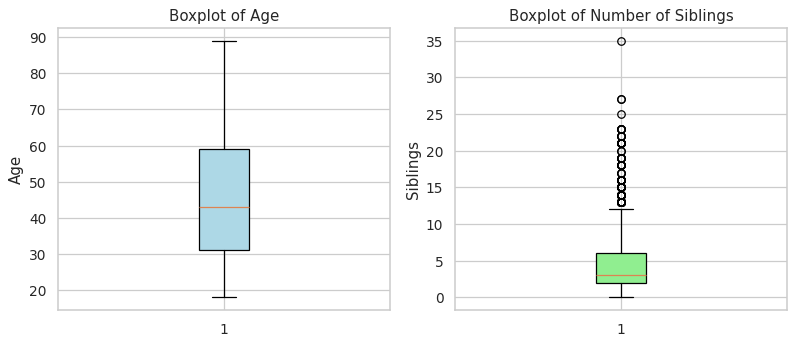

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].boxplot(df_clean["age"], patch_artist=True, boxprops=dict(facecolor="lightblue"))
axes[0].set_title("Boxplot of Age"); axes[0].set_ylabel("Age")
axes[1].boxplot(df_clean["siblings"], patch_artist=True, boxprops=dict(facecolor="lightgreen"))
axes[1].set_title("Boxplot of Number of Siblings"); axes[1].set_ylabel("Siblings")
plt.tight_layout(); plt.show()

**Q15.** Identify outliers using the IQR method.

In [ ]:
Q1 = df_clean["siblings"].quantile(0.25)
Q3 = df_clean["siblings"].quantile(0.75)
IQR_val = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR_val
upper_bound = Q3 + 1.5 * IQR_val
print("Lower bound:", lower_bound, " Upper bound:", upper_bound)

outliers_siblings = df_clean[(df_clean["siblings"] < lower_bound) | (df_clean["siblings"] > upper_bound)]
print(len(outliers_siblings))
outliers_siblings.head()

Lower bound: -4.0  Upper bound: 12.0
194


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant,ethnicity_upper,city16_lower
17,18,1,52,14,2002,21,20.0,other,no,yes,no,OTHER,no
147,148,8,68,5,2002,15,15.0,cauc,yes,no,no,CAUC,yes
148,149,0,35,13,2002,15,22.0,other,yes,no,no,OTHER,yes
154,155,2,25,11,2002,15,17.0,other,no,yes,no,OTHER,no
197,198,3,52,5,2002,15,22.0,other,yes,no,yes,OTHER,yes


**Q16.** Remove extreme outliers.

In [ ]:
df_no_outliers = df_clean[(df_clean["siblings"] >= lower_bound) & (df_clean["siblings"] <= upper_bound)]
print(df_clean.shape)
print(df_no_outliers.shape)
df_clean = df_no_outliers

(9120, 13)
(8926, 13)


**Q17.** Histogram of a numerical variable.

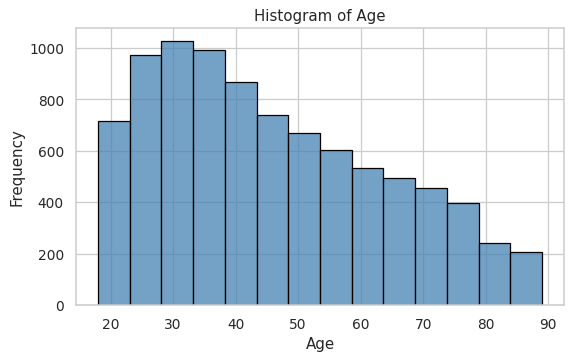

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(df_clean["age"], binwidth=5, color="steelblue", edgecolor="black")
plt.title("Histogram of Age"); plt.xlabel("Age"); plt.ylabel("Frequency")
plt.show()

**Q18.** Add a density curve to the histogram.

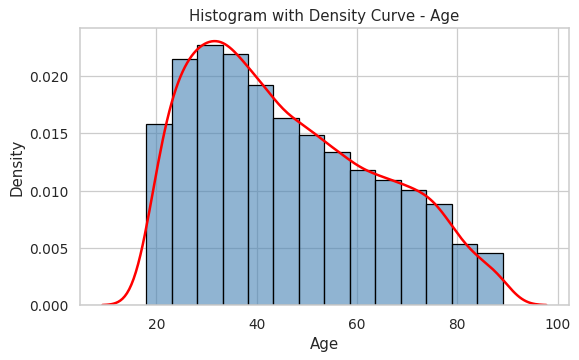

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(df_clean["age"], binwidth=5, stat="density", color="steelblue", edgecolor="black", alpha=0.6)
sns.kdeplot(df_clean["age"], color="red", linewidth=2)
plt.title("Histogram with Density Curve - Age"); plt.xlabel("Age"); plt.ylabel("Density")
plt.show()

**Q19.** Violin plot.

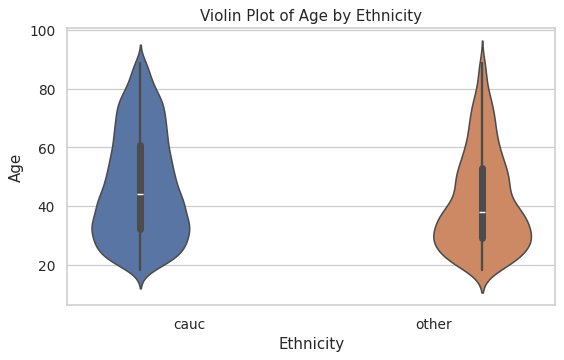

In [ ]:
plt.figure(figsize=(7, 4))
sns.violinplot(data=df_clean, x="ethnicity", y="age", hue="ethnicity", legend=False)
plt.title("Violin Plot of Age by Ethnicity"); plt.xlabel("Ethnicity"); plt.ylabel("Age")
plt.show()

**Q20.** Dot plot for a small numerical sample.

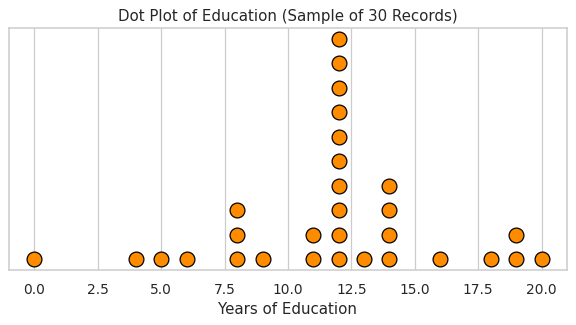

In [ ]:
small_sample = df_clean.sample(n=30, random_state=1)
counts = small_sample["education"].round().value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
for val, n in counts.items():
    ax.scatter([val] * n, range(1, n + 1), s=140, color="darkorange", edgecolor="black")
ax.set_title("Dot Plot of Education (Sample of 30 Records)")
ax.set_xlabel("Years of Education"); ax.set_yticks([])
plt.show()

**Q21.** Frequency table for a categorical variable.

In [ ]:
freq_table = df_clean["ethnicity"].value_counts()
freq_table

ethnicity
cauc     7234
other    1692
Name: count, dtype: int64

**Q22.** Proportion and percentage of each category.

In [ ]:
prop_table = freq_table / freq_table.sum()
pd.DataFrame({
    "Category": freq_table.index,
    "Frequency": freq_table.values,
    "Proportion": prop_table.round(4).values,
    "Percentage": (prop_table * 100).round(2).values,
})

,Category,Frequency,Proportion,Percentage
0,cauc,7234,0.8104,81.04
1,other,1692,0.1896,18.96


**Q23.** Bar chart of frequencies.

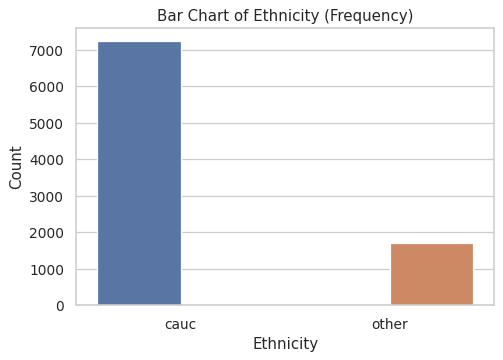

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="ethnicity", hue="ethnicity", legend=False)
plt.title("Bar Chart of Ethnicity (Frequency)"); plt.xlabel("Ethnicity"); plt.ylabel("Count")
plt.show()

**Q24.** Horizontal bar chart.

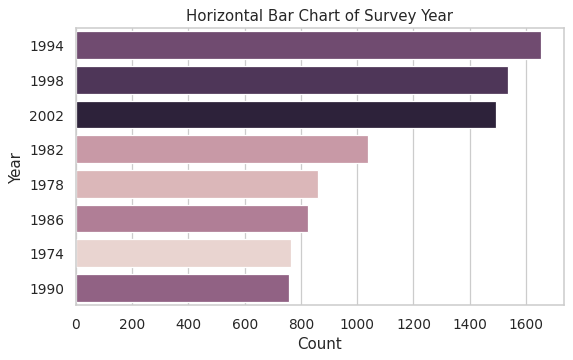

In [ ]:
order = df_clean["year"].value_counts().index
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, y="year", order=order, hue="year", legend=False, orient="h")
plt.title("Horizontal Bar Chart of Survey Year"); plt.xlabel("Count"); plt.ylabel("Year")
plt.show()

**Q25.** Percentage bar chart.

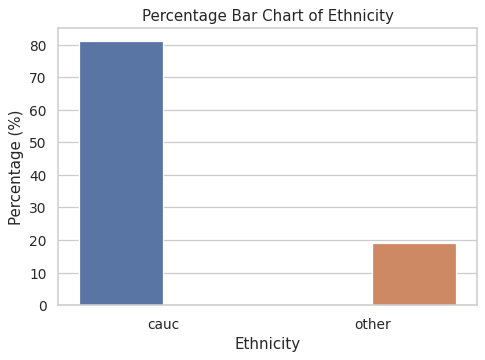

In [ ]:
pct = df_clean["ethnicity"].value_counts(normalize=True) * 100
plt.figure(figsize=(6, 4))
sns.barplot(x=pct.index, y=pct.values, hue=pct.index, legend=False)
plt.title("Percentage Bar Chart of Ethnicity"); plt.xlabel("Ethnicity"); plt.ylabel("Percentage (%)")
plt.show()

**Q26.** Pie chart.

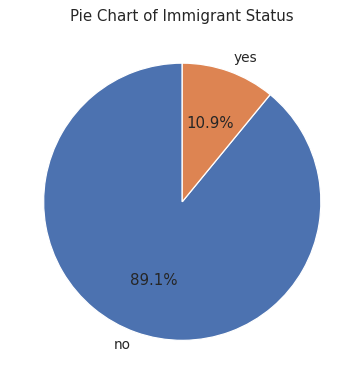

In [ ]:
pie_data = df_clean["immigrant"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(pie_data.values, labels=pie_data.index, autopct="%1.1f%%", startangle=90)
plt.title("Pie Chart of Immigrant Status")
plt.show()

**Q27.** Lollipop chart.

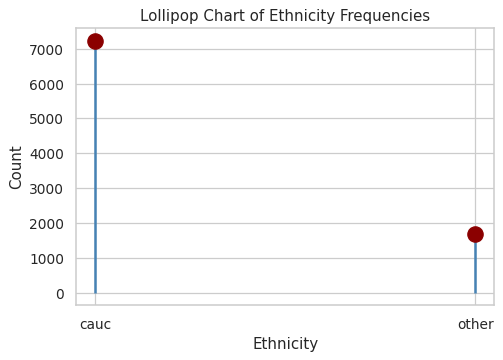

In [ ]:
lollipop_data = df_clean["ethnicity"].value_counts()
plt.figure(figsize=(6, 4))
plt.vlines(lollipop_data.index.astype(str), 0, lollipop_data.values, color="steelblue", linewidth=2)
plt.scatter(lollipop_data.index.astype(str), lollipop_data.values, s=150, color="darkred", zorder=3)
plt.title("Lollipop Chart of Ethnicity Frequencies"); plt.xlabel("Ethnicity"); plt.ylabel("Count")
plt.show()

**Q28.** Dot chart.

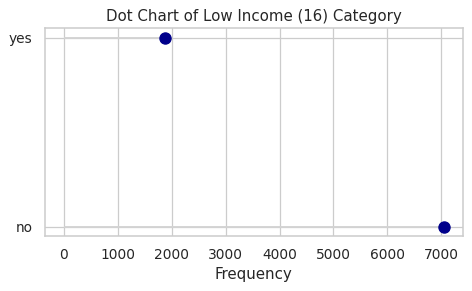

In [ ]:
t = df_clean["lowincome16"].value_counts().sort_index()
plt.figure(figsize=(6, 3))
plt.hlines(t.index.astype(str), 0, t.values, color="lightgray")
plt.scatter(t.values, t.index.astype(str), color="darkblue", s=80, zorder=3)
plt.title("Dot Chart of Low Income (16) Category"); plt.xlabel("Frequency")
plt.show()

**Q29.** Density plot.

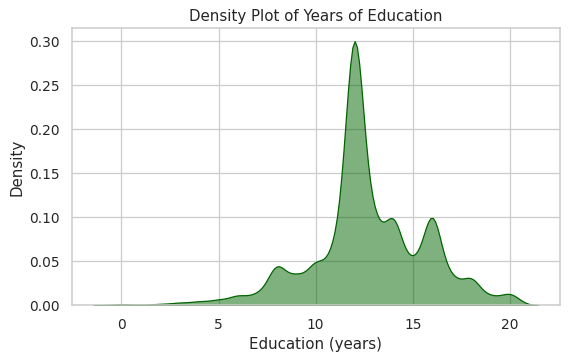

In [ ]:
plt.figure(figsize=(7, 4))
sns.kdeplot(df_clean["education"], fill=True, color="darkgreen", alpha=0.5)
plt.title("Density Plot of Years of Education"); plt.xlabel("Education (years)"); plt.ylabel("Density")
plt.show()

**Q30.** Faceting — distribution of one variable across groups.

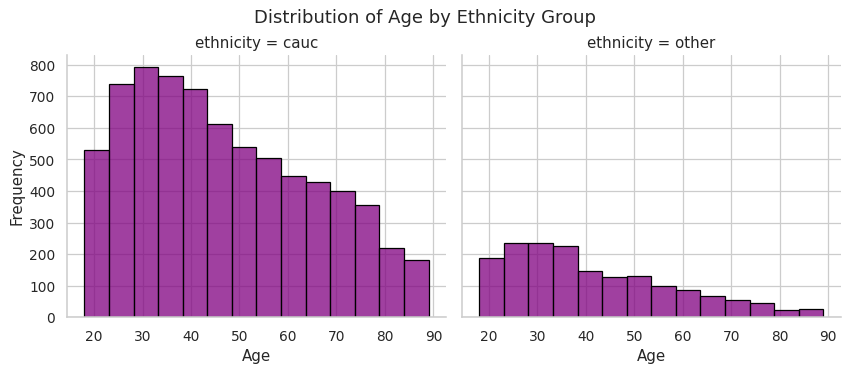

In [ ]:
g = sns.FacetGrid(df_clean, col="ethnicity", height=4, aspect=1.2)
g.map_dataframe(sns.histplot, x="age", binwidth=5, color="purple", edgecolor="black")
g.set_axis_labels("Age", "Frequency")
g.fig.suptitle("Distribution of Age by Ethnicity Group", y=1.03)
plt.show()

---
# ASSESSMENT V — Multivariate Analysis
*Multivariate Data Visualization on the GSS7402 Dataset — Adharsh, 23BDS0029*

**Q1.** Load the dataset; identify numerical and categorical variables.

In [ ]:
gss = pd.read_excel(data_path)

print("\n===== Dataset dimensions =====")
print(gss.shape)
print("\n===== Structure of the dataset =====")
gss.info()
print("\n===== First few rows =====")
display(gss.head())
print("\n===== Summary statistics =====")
display(gss.describe(include="all"))

for c in gss.select_dtypes(include="object").columns:
    gss[c] = gss[c].astype("category")

numerical_vars = list(gss.select_dtypes(include="number").columns)
categorical_vars = list(gss.select_dtypes(include="category").columns)
print("\n===== Numerical variables =====");   print(numerical_vars)
print("\n===== Categorical variables =====");  print(categorical_vars)
gss_afb = gss[gss["agefirstbirth"].notna()]


===== Dataset dimensions =====
(9120, 11)

===== Structure of the dataset =====
<class 'pandas.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   rownames       9120 non-null   int64  
 1   kids           9120 non-null   int64  
 2   age            9120 non-null   int64  
 3   education      9120 non-null   int64  
 4   year           9120 non-null   int64  
 5   siblings       9120 non-null   int64  
 6   agefirstbirth  3312 non-null   float64
 7   ethnicity      9120 non-null   str    
 8   city16         9120 non-null   str    
 9   lowincome16    9120 non-null   str    
 10  immigrant      9120 non-null   str    
dtypes: float64(1), int64(6), str(4)
memory usage: 783.9 KB

===== First few rows =====


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
0,1,0,25,14,2002,1,NaN,cauc,no,no,no
1,2,1,30,13,2002,4,19.0,cauc,yes,no,no
2,3,1,55,2,2002,1,27.0,cauc,no,no,yes
3,4,2,57,16,2002,1,22.0,cauc,no,no,no
4,5,2,71,12,2002,6,29.0,cauc,yes,no,no



===== Summary statistics =====


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
count,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,3312.000000,9120,9120,9120,9120
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cauc,no,no,no
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7335,5246,7182,8122
mean,4560.500000,2.076096,46.082018,12.635088,1990.288596,4.050658,22.630737,NaN,NaN,NaN,NaN
std,2632.861561,1.805099,17.923889,2.955190,9.096915,3.246137,4.859220,NaN,NaN,NaN,NaN
min,1.000000,0.000000,18.000000,0.000000,1974.000000,0.000000,9.000000,NaN,NaN,NaN,NaN
25%,2280.750000,1.000000,31.000000,12.000000,1982.000000,2.000000,19.000000,NaN,NaN,NaN,NaN
50%,4560.500000,2.000000,43.000000,12.000000,1994.000000,3.000000,22.000000,NaN,NaN,NaN,NaN
75%,6840.250000,3.000000,59.000000,14.000000,1998.000000,6.000000,25.000000,NaN,NaN,NaN,NaN



===== Numerical variables =====
['rownames', 'kids', 'age', 'education', 'year', 'siblings', 'agefirstbirth']

===== Categorical variables =====
['ethnicity', 'city16', 'lowincome16', 'immigrant']


**Q2.** Scatter plot with three variables (x, y, colour).

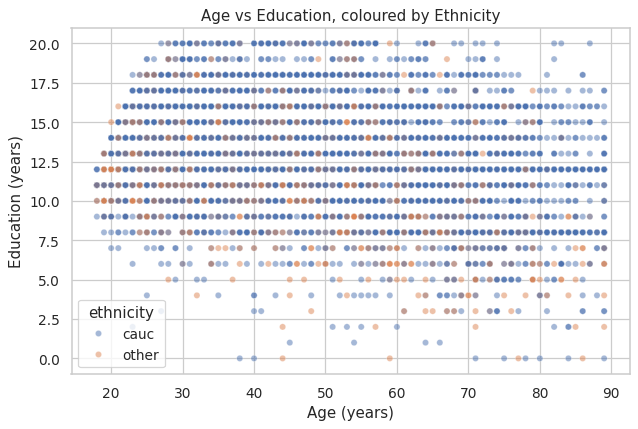

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=gss, x="age", y="education", hue="ethnicity", alpha=0.5, s=25)
plt.title("Age vs Education, coloured by Ethnicity")
plt.xlabel("Age (years)"); plt.ylabel("Education (years)")
plt.show()

**Q3.** Scatter plot with four variables (x, y, colour, shape).

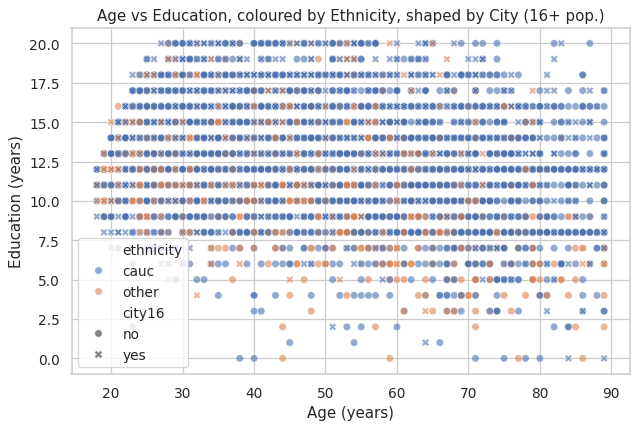

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=gss, x="age", y="education", hue="ethnicity", style="city16", alpha=0.6, s=35)
plt.title("Age vs Education, coloured by Ethnicity, shaped by City (16+ pop.)")
plt.xlabel("Age (years)"); plt.ylabel("Education (years)")
plt.show()

**Q4.** Scatter plot with four variables (x, y, colour, size).

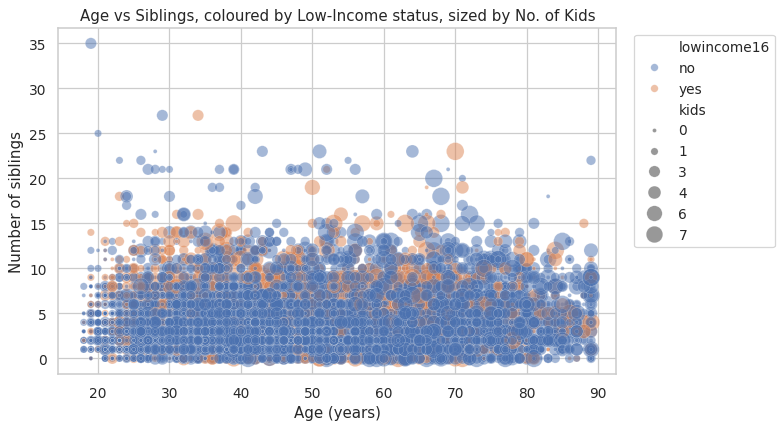

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=gss, x="age", y="siblings", hue="lowincome16", size="kids",
                sizes=(10, 200), alpha=0.5)
plt.title("Age vs Siblings, coloured by Low-Income status, sized by No. of Kids")
plt.xlabel("Age (years)"); plt.ylabel("Number of siblings")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Q5.** Bubble plot using three numerical variables.

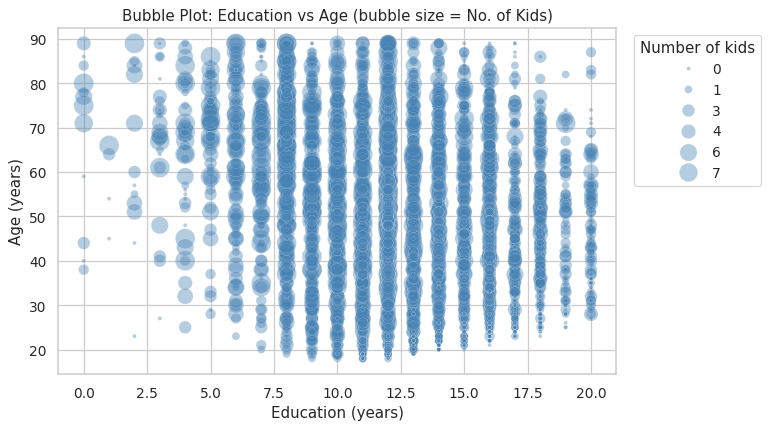

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=gss, x="education", y="age", size="kids", sizes=(10, 250),
                alpha=0.4, color="steelblue")
plt.title("Bubble Plot: Education vs Age (bubble size = No. of Kids)")
plt.xlabel("Education (years)"); plt.ylabel("Age (years)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Number of kids")
plt.show()

**Q6.** Subplots using faceting by one variable.

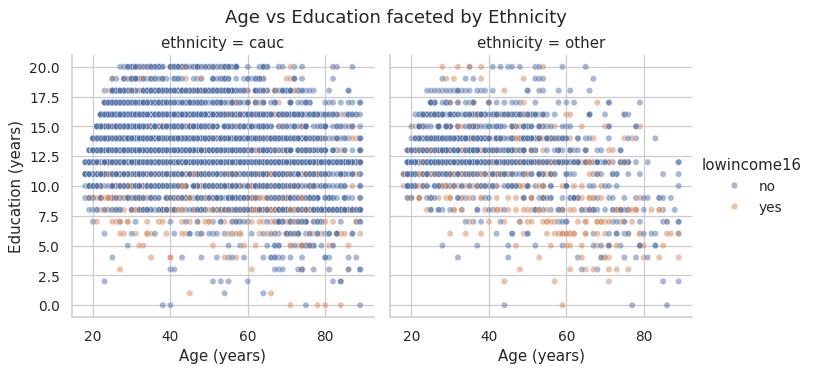

In [ ]:
g = sns.relplot(data=gss, x="age", y="education", hue="lowincome16", col="ethnicity",
                col_wrap=2, alpha=0.5, s=25, height=4)
g.set_axis_labels("Age (years)", "Education (years)")
g.fig.suptitle("Age vs Education faceted by Ethnicity", y=1.03)
plt.show()

**Q7.** Subplots using a facet grid (two categorical variables).

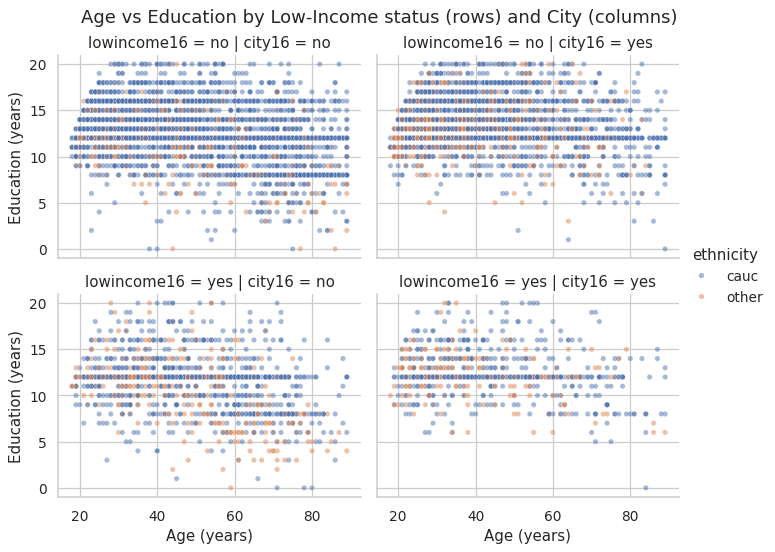

In [ ]:
g = sns.relplot(data=gss, x="age", y="education", hue="ethnicity",
                row="lowincome16", col="city16", alpha=0.5, s=18, height=3, aspect=1.3)
g.set_axis_labels("Age (years)", "Education (years)")
g.fig.suptitle("Age vs Education by Low-Income status (rows) and City (columns)", y=1.02)
plt.show()

**Q8.** Pairs plot using at least four numerical variables.

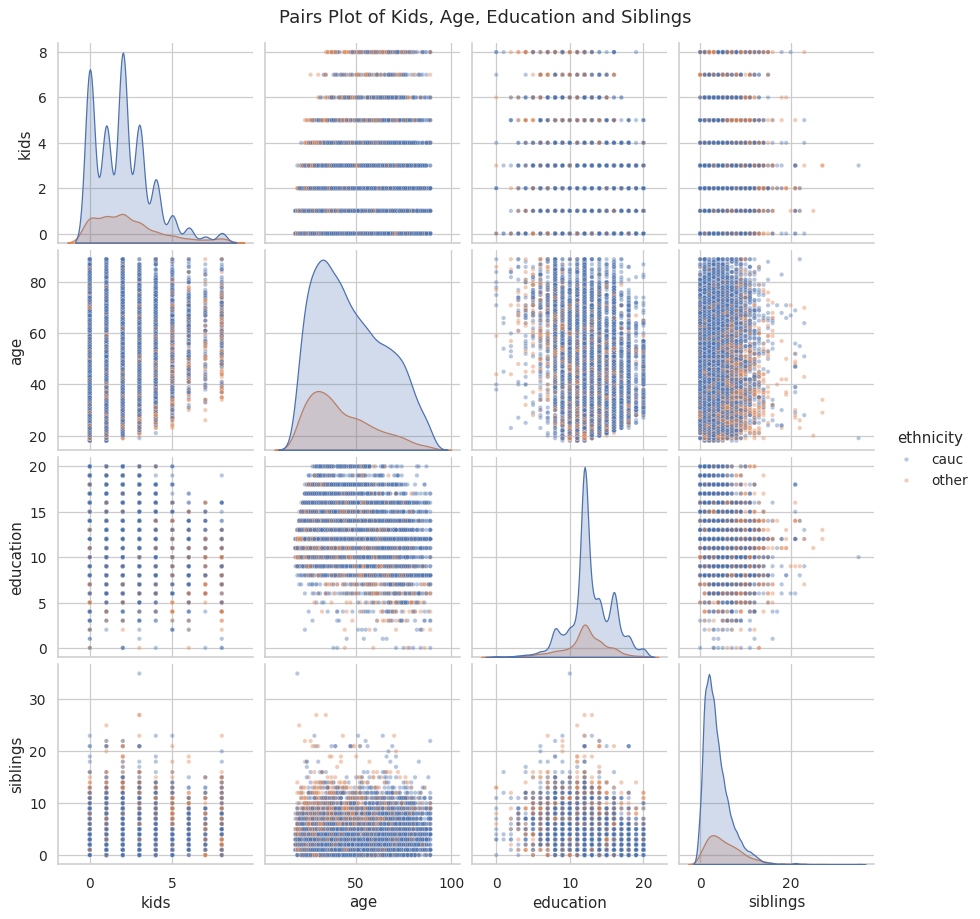

In [ ]:
pairs_vars = ["kids", "age", "education", "siblings"]
g = sns.pairplot(gss, vars=pairs_vars, hue="ethnicity", plot_kws=dict(alpha=0.4, s=12), corner=False)
g.fig.suptitle("Pairs Plot of Kids, Age, Education and Siblings", y=1.02)
plt.show()

**Q9.** Parallel coordinate plot.

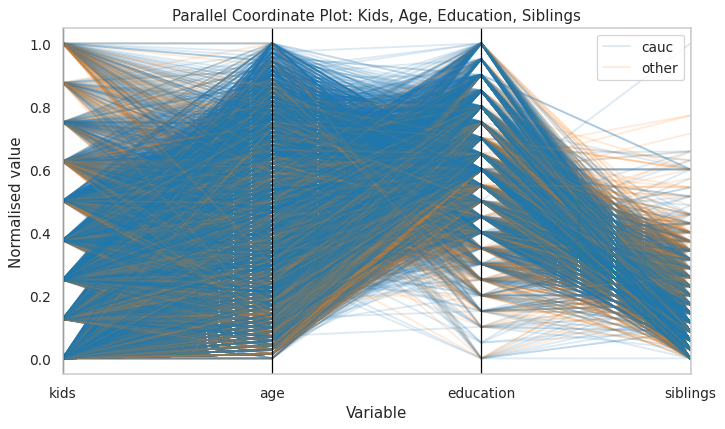

In [ ]:
from pandas.plotting import parallel_coordinates

parcoord_vars = ["kids", "age", "education", "siblings"]
pc = gss[parcoord_vars].copy()
pc = (pc - pc.min()) / (pc.max() - pc.min())      # uniminmax scaling
pc["ethnicity"] = gss["ethnicity"].astype(str).values

plt.figure(figsize=(9, 5))
parallel_coordinates(pc, "ethnicity", alpha=0.15, color=["#1f77b4", "#ff7f0e"])
plt.title("Parallel Coordinate Plot: Kids, Age, Education, Siblings")
plt.xlabel("Variable"); plt.ylabel("Normalised value")
plt.show()

---
# ASSESSMENT VI — Time Series Analysis
Dataset: the classic `AirPassengers` series (monthly airline passengers, 1949-1960), embedded below so no download is needed.

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

**Q1.** Load the AirPassengers dataset.

In [ ]:
ap_values = [
    112,118,132,129,121,135,148,148,136,119,104,118,
    115,126,141,135,125,149,170,170,158,133,114,140,
    145,150,178,163,172,178,199,199,184,162,146,166,
    171,180,193,181,183,218,230,242,209,191,172,194,
    196,196,236,235,229,243,264,272,237,211,180,201,
    204,188,235,227,234,264,302,293,259,229,203,229,
    242,233,267,269,270,315,364,347,312,274,237,278,
    284,277,317,313,318,374,413,405,355,306,271,306,
    315,301,356,348,355,422,465,467,404,347,305,336,
    340,318,362,348,363,435,491,505,404,359,310,337,
    360,342,406,396,420,472,548,559,463,407,362,405,
    417,391,419,461,472,535,622,606,508,461,390,432,
]
ap = pd.Series(ap_values, index=pd.date_range("1949-01-01", periods=144, freq="MS"), name="AirPassengers")

**Q2.** First five and last five observations.

In [ ]:
print("First five observations:")
print(ap.head(5))
print("\nLast five observations:")
print(ap.tail(5))

First five observations:
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: AirPassengers, dtype: int64

Last five observations:
1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: AirPassengers, dtype: int64


**Q3.** Starting and ending time periods.

In [ ]:
print("Start period:", (ap.index[0].year, ap.index[0].month))
print("End period:", (ap.index[-1].year, ap.index[-1].month))

Start period: (1949, 1)
End period: (1960, 12)


**Q4.** Frequency and time-series characteristics.

In [ ]:
print("Frequency:", 12, "(monthly)")
print("Index type:", type(ap.index).__name__)
print("\nSummary of the series:")
print(ap.describe())

Frequency: 12 (monthly)
Index type: DatetimeIndex

Summary of the series:
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: AirPassengers, dtype: float64


**Q5.** Visualize the monthly passenger trend.

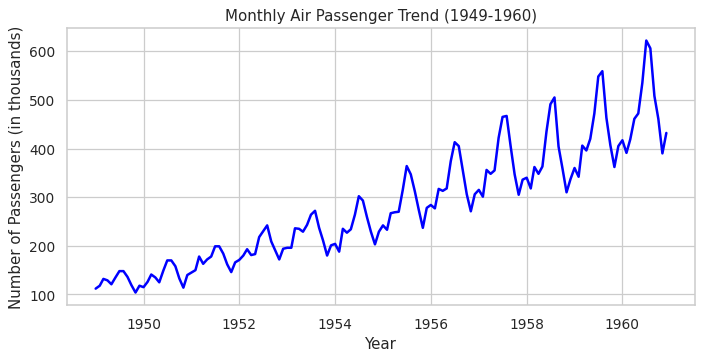

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(ap, color="blue", linewidth=2)
plt.title("Monthly Air Passenger Trend (1949-1960)")
plt.xlabel("Year"); plt.ylabel("Number of Passengers (in thousands)")
plt.grid(True)
plt.show()

**Q6.** Decompose into trend, seasonal and random components (multiplicative).

In [ ]:
decomposed_ap = seasonal_decompose(ap, model="multiplicative", period=12)
print("Seasonal figures (one per month):")
print(decomposed_ap.seasonal.head(12).round(4))
print("\nTrend (first 12 values - NaN at the edges):")
print(decomposed_ap.trend.head(12))
print("\nRandom component (first 12 values):")
print(decomposed_ap.resid.head(12))

Seasonal figures (one per month):
1949-01-01    0.9102
1949-02-01    0.8836
1949-03-01    1.0074
1949-04-01    0.9759
1949-05-01    0.9814
1949-06-01    1.1128
1949-07-01    1.2266
1949-08-01    1.2199
1949-09-01    1.0605
1949-10-01    0.9218
1949-11-01    0.8012
1949-12-01    0.8988
Freq: MS, Name: seasonal, dtype: float64

Trend (first 12 values - NaN at the edges):
1949-01-01           NaN
1949-02-01           NaN
1949-03-01           NaN
1949-04-01           NaN
1949-05-01           NaN
1949-06-01           NaN
1949-07-01    126.791667
1949-08-01    127.250000
1949-09-01    127.958333
1949-10-01    128.583333
1949-11-01    129.000000
1949-12-01    129.750000
Freq: MS, Name: trend, dtype: float64

Random component (first 12 values):
1949-01-01         NaN
1949-02-01         NaN
1949-03-01         NaN
1949-04-01         NaN
1949-05-01         NaN
1949-06-01         NaN
1949-07-01    0.951664
1949-08-01    0.953401
1949-09-01    1.002220
1949-10-01    1.004028
1949-11-01    1.006270


**Q7.** Plot the decomposed components.

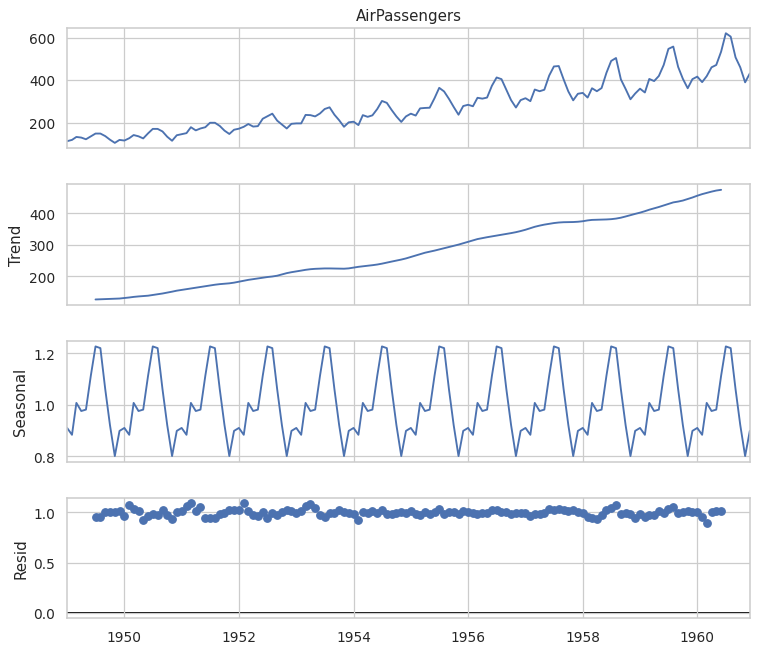

In [ ]:
fig = decomposed_ap.plot()
fig.set_size_inches(9, 8)
plt.show()

**Q8.** ACF and PACF.

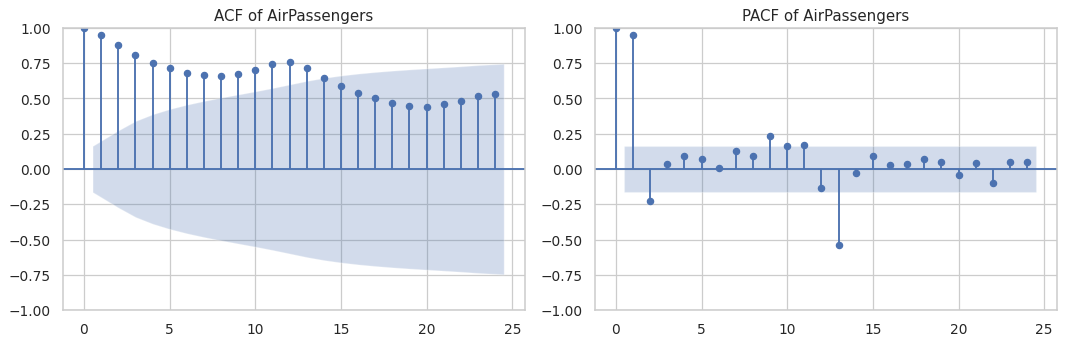

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ap, lags=24, ax=axes[0]);  axes[0].set_title("ACF of AirPassengers")
plot_pacf(ap, lags=24, ax=axes[1]); axes[1].set_title("PACF of AirPassengers")
plt.tight_layout(); plt.show()

**Q9.** Fit an ARIMA model.  
Python has no built-in `auto.arima`, so the best seasonal ARIMA (period 12, d = 1, D = 1) is chosen by a small grid search that minimises AIC.

In [ ]:
best_model, best_aic, best_cfg = None, np.inf, None
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = SARIMAX(ap, order=(p, 1, q), seasonal_order=(P, 1, Q, 12),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    except Exception:
        continue
    if m.aic < best_aic:
        best_model, best_aic, best_cfg = m, m.aic, ((p, 1, q), (P, 1, Q, 12))
arima_model = best_model
print("Best model: ARIMA%s x %s   (AIC = %.2f)" % (best_cfg[0], best_cfg[1], best_aic))

Best model: ARIMA(2, 1, 2) x (0, 1, 1, 12)   (AIC = 911.70)


**Q10.** Display and interpret the fitted ARIMA model.

In [ ]:
print(arima_model.summary())
print("\nModel coefficients:")
print(arima_model.params)
print("\nInterpretation:")
print("The grid search selected an ARIMA", best_cfg[0], "seasonal", best_cfg[1],
      "model with a seasonal period of 12 months.")
print("AIC:", round(arima_model.aic, 2), "| BIC:", round(arima_model.bic, 2),
      "| Log-likelihood:", round(arima_model.llf, 2))

                                      SARIMAX Results                                       
Dep. Variable:                        AirPassengers   No. Observations:                  144
Model:             SARIMAX(2, 1, 2)x(0, 1, [1], 12)   Log Likelihood                -449.849
Date:                              Sun, 01 Nov 2026   AIC                            911.698
Time:                                      13:58:26   BIC                            928.220
Sample:                                  01-01-1949   HQIC                           918.405
                                       - 12-01-1960                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3828      0.436      0.879      0.379      -0.471       1.236
ar.L2          0.36

**Q11.** Forecast the next 12 months.

In [ ]:
fc = arima_model.get_forecast(steps=12)
forecast_mean = fc.predicted_mean
forecast_se = fc.se_mean
print("Forecasted values for the next 12 months:")
print(forecast_mean.round(2))
print("\nStandard errors of the forecast:")
print(forecast_se.round(2))

Forecasted values for the next 12 months:
1961-01-01    444.22
1961-02-01    420.12
1961-03-01    451.84
1961-04-01    488.81
1961-05-01    501.30
1961-06-01    563.61
1961-07-01    649.40
1961-08-01    636.42
1961-09-01    538.75
1961-10-01    491.02
1961-11-01    422.80
1961-12-01    464.81
Freq: MS, Name: predicted_mean, dtype: float64

Standard errors of the forecast:
1961-01-01    11.62
1961-02-01    13.60
1961-03-01    15.32
1961-04-01    16.24
1961-05-01    16.92
1961-06-01    17.36
1961-07-01    17.67
1961-08-01    17.89
1961-09-01    18.04
1961-10-01    18.16
1961-11-01    18.24
1961-12-01    18.30
Freq: MS, Name: var_pred_mean, dtype: float64


**Q12.** Actual vs forecasted values.

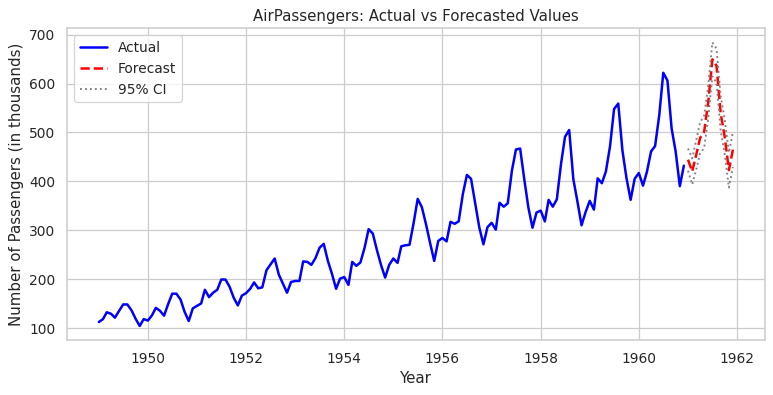

In [ ]:
ci = fc.conf_int(alpha=0.05)
plt.figure(figsize=(10, 4.5))
plt.plot(ap, color="blue", linewidth=2, label="Actual")
plt.plot(forecast_mean, color="red", linestyle="--", linewidth=2, label="Forecast")
plt.plot(ci.index, ci.iloc[:, 0], color="gray", linestyle=":", label="95% CI")
plt.plot(ci.index, ci.iloc[:, 1], color="gray", linestyle=":")
plt.title("AirPassengers: Actual vs Forecasted Values")
plt.xlabel("Year"); plt.ylabel("Number of Passengers (in thousands)")
plt.legend(loc="upper left")
plt.show()

---
# ASSESSMENT VII — 1D, 2D and ND Analysis

**Q1.** Load the dataset.

In [ ]:
data = pd.read_excel(data_path)
display(data.head())
data.info()
print(data.shape)
print(list(data.columns))
data.describe(include="all")

,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
0,1,0,25,14,2002,1,NaN,cauc,no,no,no
1,2,1,30,13,2002,4,19.0,cauc,yes,no,no
2,3,1,55,2,2002,1,27.0,cauc,no,no,yes
3,4,2,57,16,2002,1,22.0,cauc,no,no,no
4,5,2,71,12,2002,6,29.0,cauc,yes,no,no


<class 'pandas.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   rownames       9120 non-null   int64  
 1   kids           9120 non-null   int64  
 2   age            9120 non-null   int64  
 3   education      9120 non-null   int64  
 4   year           9120 non-null   int64  
 5   siblings       9120 non-null   int64  
 6   agefirstbirth  3312 non-null   float64
 7   ethnicity      9120 non-null   str    
 8   city16         9120 non-null   str    
 9   lowincome16    9120 non-null   str    
 10  immigrant      9120 non-null   str    
dtypes: float64(1), int64(6), str(4)
memory usage: 783.9 KB
(9120, 11)
['rownames', 'kids', 'age', 'education', 'year', 'siblings', 'agefirstbirth', 'ethnicity', 'city16', 'lowincome16', 'immigrant']


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
count,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,3312.000000,9120,9120,9120,9120
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cauc,no,no,no
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7335,5246,7182,8122
mean,4560.500000,2.076096,46.082018,12.635088,1990.288596,4.050658,22.630737,NaN,NaN,NaN,NaN
std,2632.861561,1.805099,17.923889,2.955190,9.096915,3.246137,4.859220,NaN,NaN,NaN,NaN
min,1.000000,0.000000,18.000000,0.000000,1974.000000,0.000000,9.000000,NaN,NaN,NaN,NaN
25%,2280.750000,1.000000,31.000000,12.000000,1982.000000,2.000000,19.000000,NaN,NaN,NaN,NaN
50%,4560.500000,2.000000,43.000000,12.000000,1994.000000,3.000000,22.000000,NaN,NaN,NaN,NaN
75%,6840.250000,3.000000,59.000000,14.000000,1998.000000,6.000000,25.000000,NaN,NaN,NaN,NaN


**Q2.** Missing values and duplicates check.

In [ ]:
print(data.isna().sum())
print("Duplicated rows:", data.duplicated().sum())

rownames            0
kids                0
age                 0
education           0
year                0
siblings            0
agefirstbirth    5808
ethnicity           0
city16              0
lowincome16         0
immigrant           0
dtype: int64
Duplicated rows: 0


**Q3.** Summary statistics (Mean, Median, Min, Max, Range, Variance, SD, IQR, Skewness, Kurtosis) stored in a data frame.

In [ ]:
x = data["age"]
summary_statistics = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum", "Range", "Variance",
                  "Standard Deviation", "IQR", "Skewness", "Kurtosis"],
    "Value": [
        x.mean(), x.median(), x.min(), x.max(), x.max() - x.min(),
        x.var(ddof=1), x.std(ddof=1), x.quantile(0.75) - x.quantile(0.25),
        skewness(x), kurtosis(x),
    ],
})
print(summary_statistics)

            Statistic       Value
0                Mean   46.082018
1              Median   43.000000
2             Minimum   18.000000
3             Maximum   89.000000
4               Range   71.000000
5            Variance  321.265780
6  Standard Deviation   17.923889
7                 IQR   28.000000
8            Skewness    0.476425
9            Kurtosis   -0.780924


**Q4.** Frequency / relative frequency tables, pie chart and bar plot for a categorical variable.

ethnicity
cauc     7335
other    1785
Name: count, dtype: int64
ethnicity
cauc     0.804276
other    0.195724
Name: count, dtype: float64
ethnicity
cauc     80.427632
other    19.572368
Name: count, dtype: float64


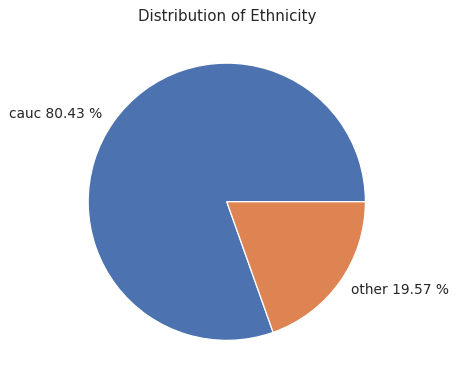

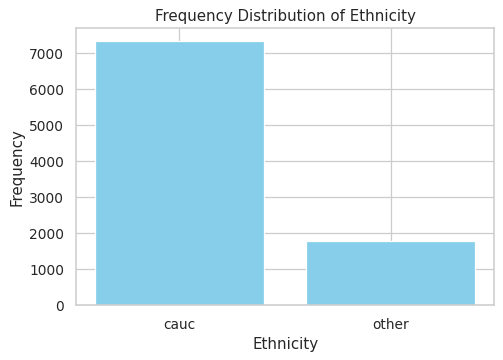

In [ ]:
freq_ethnicity = data["ethnicity"].value_counts()
print(freq_ethnicity)
print(freq_ethnicity / freq_ethnicity.sum())
print(freq_ethnicity / freq_ethnicity.sum() * 100)

plt.figure(figsize=(5, 5))
plt.pie(freq_ethnicity.values,
        labels=[f"{k} {v:.2f} %" for k, v in zip(freq_ethnicity.index, freq_ethnicity / freq_ethnicity.sum() * 100)])
plt.title("Distribution of Ethnicity")
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(freq_ethnicity.index.astype(str), freq_ethnicity.values, color="skyblue")
plt.title("Frequency Distribution of Ethnicity"); plt.xlabel("Ethnicity"); plt.ylabel("Frequency")
plt.show()

**Q5.** Binned frequency table, histogram and box plot for a numerical variable.

18 89
age
[10, 20)     131
[20, 30)    1774
[30, 40)    2065
[40, 50)    1598
[50, 60)    1279
[60, 70)    1036
[70, 80)     835
[80, 90)     402
Name: count, dtype: int64
age
[10, 20)    0.014364
[20, 30)    0.194518
[30, 40)    0.226425
[40, 50)    0.175219
[50, 60)    0.140241
[60, 70)    0.113596
[70, 80)    0.091557
[80, 90)    0.044079
Name: count, dtype: float64


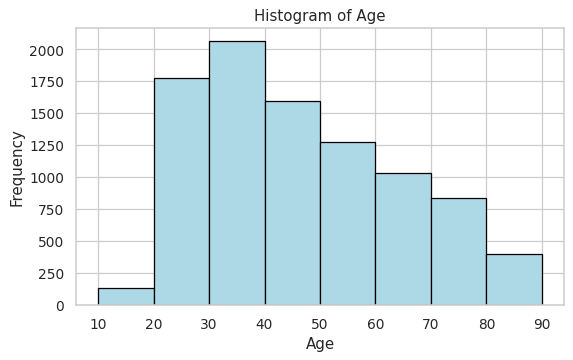

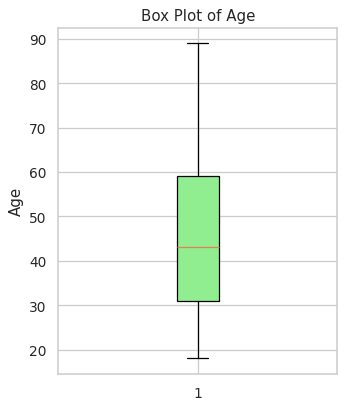

In [ ]:
print(data["age"].min(), data["age"].max())
age_breaks = np.arange(math.floor(data["age"].min() / 10) * 10,
                       math.ceil(data["age"].max() / 10) * 10 + 1, 10)
age_groups = pd.cut(data["age"], bins=age_breaks, right=False, include_lowest=True)
age_frequency = age_groups.value_counts().sort_index()
print(age_frequency)
print(age_frequency / age_frequency.sum())

plt.figure(figsize=(7, 4))
plt.hist(data["age"].dropna(), bins=age_breaks, color="lightblue", edgecolor="black")
plt.title("Histogram of Age"); plt.xlabel("Age"); plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(4, 5))
plt.boxplot(data["age"].dropna(), patch_artist=True, boxprops=dict(facecolor="lightgreen"))
plt.title("Box Plot of Age"); plt.ylabel("Age")
plt.show()

**Q6.** Contingency table and row / column percentages.

In [ ]:
contingency_table = pd.crosstab(data["ethnicity"], data["immigrant"])
print(contingency_table)

row_percentages = pd.crosstab(data["ethnicity"], data["immigrant"], normalize="index") * 100
print(row_percentages)

column_percentages = pd.crosstab(data["ethnicity"], data["immigrant"], normalize="columns") * 100
print(column_percentages)

overall_percentages = pd.crosstab(data["ethnicity"], data["immigrant"], normalize="all") * 100
print(overall_percentages)

immigrant    no  yes
ethnicity           
cauc       6618  717
other      1504  281
immigrant         no        yes
ethnicity                      
cauc       90.224949   9.775051
other      84.257703  15.742297
immigrant         no        yes
ethnicity                      
cauc       81.482393  71.843687
other      18.517607  28.156313
immigrant         no       yes
ethnicity                     
cauc       72.565789  7.861842
other      16.491228  3.081140


**Q7.** Stacked bar plot.

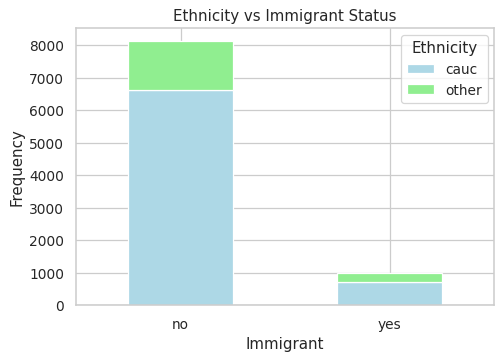

In [ ]:
contingency_table.T.plot(kind="bar", stacked=True, color=["lightblue", "lightgreen"], figsize=(6, 4), rot=0)
plt.title("Ethnicity vs Immigrant Status"); plt.xlabel("Immigrant"); plt.ylabel("Frequency")
plt.legend(title="Ethnicity")
plt.show()

**Q8.** Mean, median and SD of a numerical variable grouped by category.

In [ ]:
print(data.groupby("ethnicity")["age"].mean().reset_index())
print(data.groupby("ethnicity")["age"].median().reset_index())
print(data.groupby("ethnicity")["age"].std().reset_index())

grouped_statistics = data.groupby("ethnicity")["age"].agg(Mean="mean", Median="median", SD="std").reset_index()
print(grouped_statistics)

  ethnicity        age
0      cauc  47.097887
1     other  41.907563
  ethnicity   age
0      cauc  44.0
1     other  38.0
  ethnicity        age
0      cauc  18.082024
1     other  16.624071
  ethnicity       Mean  Median         SD
0      cauc  47.097887    44.0  18.082024
1     other  41.907563    38.0  16.624071


**Q9.** Side-by-side box plots and violin plot.

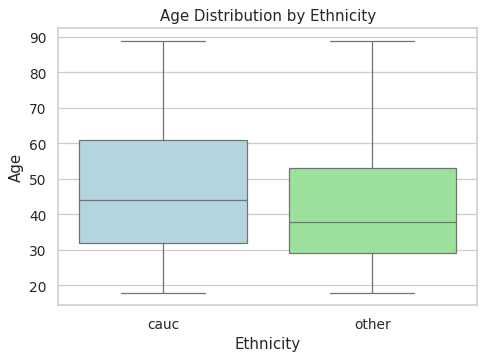

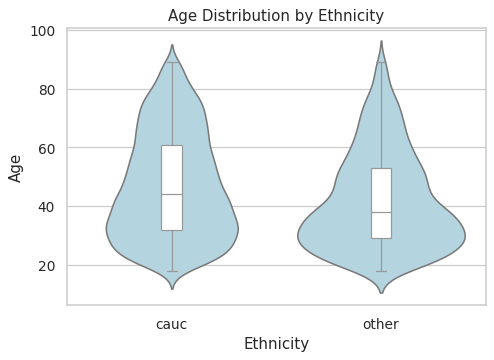

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=data, x="ethnicity", y="age", hue="ethnicity", palette=["lightblue", "lightgreen"], legend=False)
plt.title("Age Distribution by Ethnicity"); plt.xlabel("Ethnicity"); plt.ylabel("Age")
plt.show()

plt.figure(figsize=(6, 4))
sns.violinplot(data=data, x="ethnicity", y="age", color="lightblue", inner=None)
sns.boxplot(data=data, x="ethnicity", y="age", width=0.1, color="white", fliersize=0)
plt.title("Age Distribution by Ethnicity"); plt.xlabel("Ethnicity"); plt.ylabel("Age")
plt.show()

**Q10.** Pearson and Spearman correlation + scatter plot with linear trend line.

-0.24184323043772077
-0.1979366550632483
     Method  Correlation
0   Pearson    -0.241843
1  Spearman    -0.197937


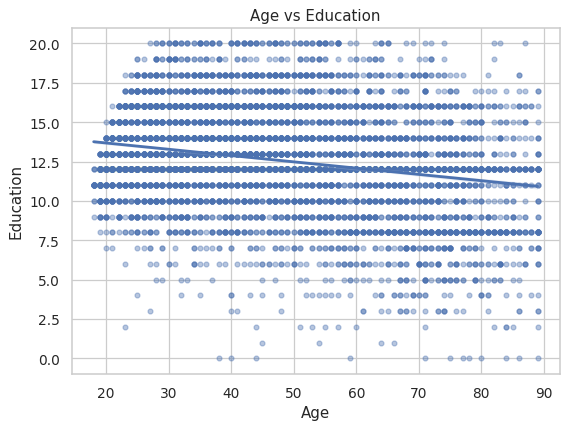

In [ ]:
pair = data[["age", "education"]].dropna()
pearson_correlation = pair["age"].corr(pair["education"], method="pearson")
spearman_correlation = pair["age"].corr(pair["education"], method="spearman")
print(pearson_correlation)
print(spearman_correlation)
print(pd.DataFrame({"Method": ["Pearson", "Spearman"],
                    "Correlation": [pearson_correlation, spearman_correlation]}))

plt.figure(figsize=(7, 5))
sns.regplot(data=data, x="age", y="education", scatter_kws=dict(alpha=0.4, s=15))
plt.title("Age vs Education"); plt.xlabel("Age"); plt.ylabel("Education")
plt.show()

**Q11.** Summary statistics across two categorical variables; faceted box plot and grouped bar chart with error bars.

  ethnicity immigrant        age
0      cauc        no  46.327289
1      cauc       yes  54.210600
2     other        no  42.553191
3     other       yes  38.451957
  ethnicity immigrant        age
0      cauc        no  17.774940
1      cauc       yes  19.313902
2     other        no  17.011165
3     other       yes  13.900874
  ethnicity immigrant       Mean         SD
0      cauc        no  46.327289  17.774940
1      cauc       yes  54.210600  19.313902
2     other        no  42.553191  17.011165
3     other       yes  38.451957  13.900874


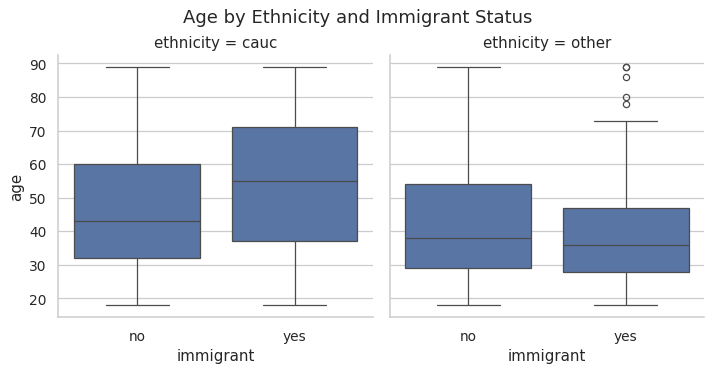

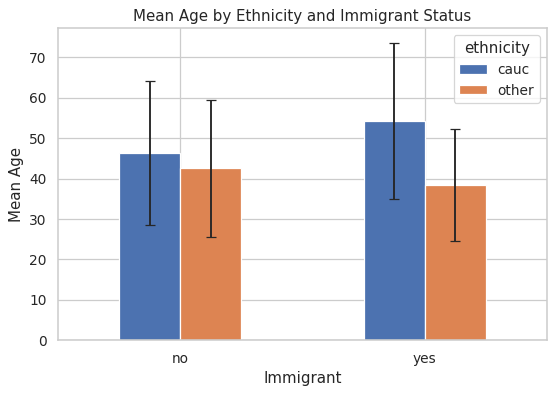

In [ ]:
print(data.groupby(["ethnicity", "immigrant"])["age"].mean().reset_index())
print(data.groupby(["ethnicity", "immigrant"])["age"].std().reset_index())

combination_summary = (data.groupby(["ethnicity", "immigrant"])["age"]
                       .agg(Mean="mean", SD="std").reset_index())
print(combination_summary)

g = sns.catplot(data=data, x="immigrant", y="age", col="ethnicity", kind="box", height=4)
g.fig.suptitle("Age by Ethnicity and Immigrant Status", y=1.03)
plt.show()

means = combination_summary.pivot(index="immigrant", columns="ethnicity", values="Mean")
sds = combination_summary.pivot(index="immigrant", columns="ethnicity", values="SD")
means.plot(kind="bar", yerr=sds, capsize=4, figsize=(7, 4.5), rot=0)
plt.title("Mean Age by Ethnicity and Immigrant Status"); plt.xlabel("Immigrant"); plt.ylabel("Mean Age")
plt.show()

**Q12.** Scatter plot coloured/shaped by category; correlation by category level.

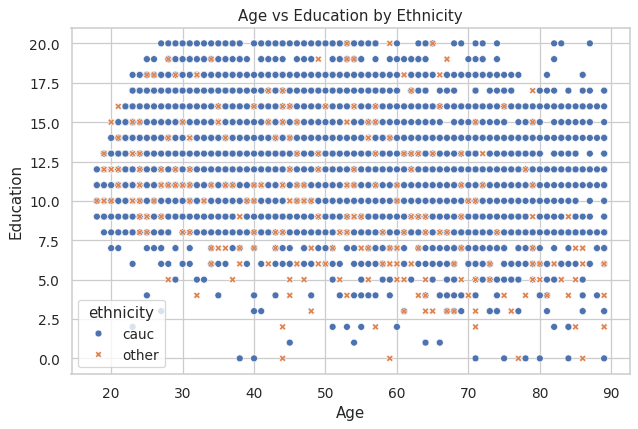

  ethnicity  Pearson_Correlation  Spearman_Correlation
0      cauc            -0.232039             -0.202245
1     other            -0.357277             -0.235953


In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x="age", y="education", hue="ethnicity", style="ethnicity", s=30)
plt.title("Age vs Education by Ethnicity"); plt.xlabel("Age"); plt.ylabel("Education")
plt.show()

cor_by_ethnicity = data.groupby("ethnicity").apply(
    lambda d: pd.Series({
        "Pearson_Correlation": d["age"].corr(d["education"], method="pearson"),
        "Spearman_Correlation": d["age"].corr(d["education"], method="spearman"),
    })
).reset_index()
print(cor_by_ethnicity)

**Q13.** Full correlation matrix and heatmap.

                   kids       age  education  siblings  agefirstbirth
kids           1.000000  0.325692  -0.290511  0.180015      -0.289395
age            0.325692  1.000000  -0.241843  0.109736       0.099229
education     -0.290511 -0.241843   1.000000 -0.290603       0.369737
siblings       0.180015  0.109736  -0.290603  1.000000      -0.114792
agefirstbirth -0.289395  0.099229   0.369737 -0.114792       1.000000


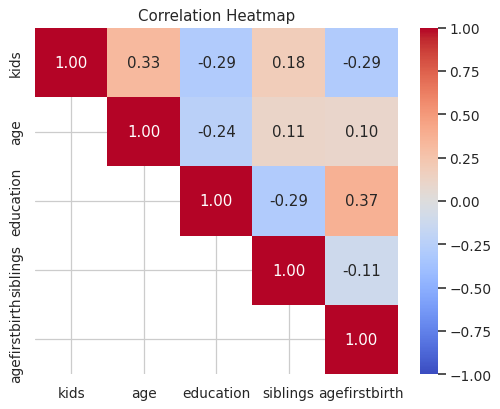

In [ ]:
numeric_data = data[["kids", "age", "education", "siblings", "agefirstbirth"]]
correlation_matrix = numeric_data.corr(method="pearson")        # pairwise-complete by default
print(correlation_matrix)

plt.figure(figsize=(6.5, 5))
mask = np.tril(np.ones_like(correlation_matrix, dtype=bool), k=-1)
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

**Q14.** Pairs plot / scatterplot matrix and summary statistics of all numeric variables.

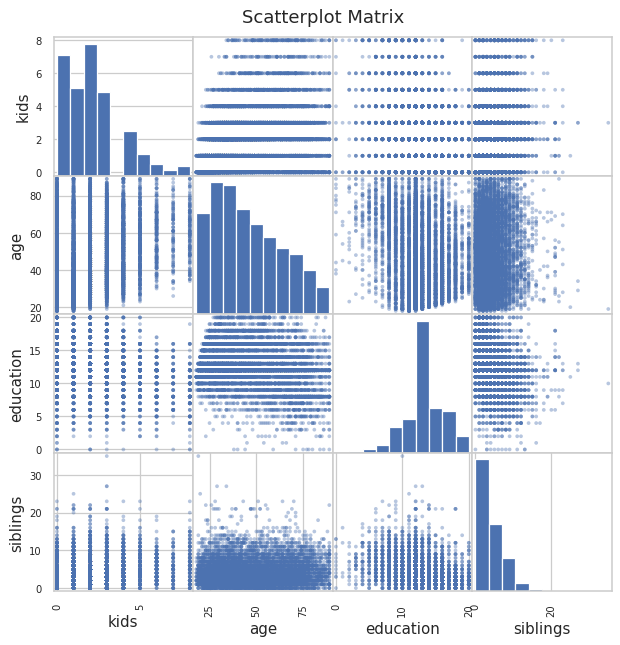

        Variable       Mean  Median  Minimum  Maximum  Range    Variance  \
0           kids   2.076096     2.0      0.0      8.0    8.0    3.258382   
1            age  46.082018    43.0     18.0     89.0   71.0  321.265780   
2      education  12.635088    12.0      0.0     20.0   20.0    8.733147   
3       siblings   4.050658     3.0      0.0     35.0   35.0   10.537405   
4  agefirstbirth  22.630737    22.0      9.0     42.0   33.0   23.612018   

          SD   IQR  Skewness  Kurtosis  
0   1.805099   2.0  0.999583  1.025595  
1  17.923889  28.0  0.476425 -0.780924  
2   2.955190   2.0 -0.261914  1.025793  
3   3.246137   4.0  1.670707  4.783655  
4   4.859220   6.0  0.867482  0.587151  


In [ ]:
pairs_data = data[["kids", "age", "education", "siblings"]]
pd.plotting.scatter_matrix(pairs_data, figsize=(8, 8), alpha=0.4, diagonal="hist")
plt.suptitle("Scatterplot Matrix", y=0.92)
plt.show()

def summary_function(x):
    x = x.dropna()
    return pd.Series({
        "Mean": x.mean(), "Median": x.median(), "Minimum": x.min(), "Maximum": x.max(),
        "Range": x.max() - x.min(), "Variance": x.var(ddof=1), "SD": x.std(ddof=1),
        "IQR": x.quantile(0.75) - x.quantile(0.25),
        "Skewness": skewness(x), "Kurtosis": kurtosis(x),
    })

all_summary_statistics = data[["kids", "age", "education", "siblings", "agefirstbirth"]].apply(summary_function).T
all_summary_statistics.insert(0, "Variable", all_summary_statistics.index)
print(all_summary_statistics.reset_index(drop=True))

---
# ASSESSMENT VIII — Clustering Techniques
## PART A: K-Means Clustering

In [ ]:
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

**Q1.** Load the dataset.

In [ ]:
data = pd.read_excel(data_path)

**Q2.** View the dataset.

In [ ]:
display(data.head())
data.info()
data.describe(include="all")

,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
0,1,0,25,14,2002,1,NaN,cauc,no,no,no
1,2,1,30,13,2002,4,19.0,cauc,yes,no,no
2,3,1,55,2,2002,1,27.0,cauc,no,no,yes
3,4,2,57,16,2002,1,22.0,cauc,no,no,no
4,5,2,71,12,2002,6,29.0,cauc,yes,no,no


<class 'pandas.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   rownames       9120 non-null   int64  
 1   kids           9120 non-null   int64  
 2   age            9120 non-null   int64  
 3   education      9120 non-null   int64  
 4   year           9120 non-null   int64  
 5   siblings       9120 non-null   int64  
 6   agefirstbirth  3312 non-null   float64
 7   ethnicity      9120 non-null   str    
 8   city16         9120 non-null   str    
 9   lowincome16    9120 non-null   str    
 10  immigrant      9120 non-null   str    
dtypes: float64(1), int64(6), str(4)
memory usage: 783.9 KB


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
count,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,3312.000000,9120,9120,9120,9120
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cauc,no,no,no
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7335,5246,7182,8122
mean,4560.500000,2.076096,46.082018,12.635088,1990.288596,4.050658,22.630737,NaN,NaN,NaN,NaN
std,2632.861561,1.805099,17.923889,2.955190,9.096915,3.246137,4.859220,NaN,NaN,NaN,NaN
min,1.000000,0.000000,18.000000,0.000000,1974.000000,0.000000,9.000000,NaN,NaN,NaN,NaN
25%,2280.750000,1.000000,31.000000,12.000000,1982.000000,2.000000,19.000000,NaN,NaN,NaN,NaN
50%,4560.500000,2.000000,43.000000,12.000000,1994.000000,3.000000,22.000000,NaN,NaN,NaN,NaN
75%,6840.250000,3.000000,59.000000,14.000000,1998.000000,6.000000,25.000000,NaN,NaN,NaN,NaN


**Q3.** Check missing values.

In [ ]:
data.isna().sum()

rownames            0
kids                0
age                 0
education           0
year                0
siblings            0
agefirstbirth    5808
ethnicity           0
city16              0
lowincome16         0
immigrant           0
dtype: int64

**Q4.** Distribution of categorical variables.

In [ ]:
for c in ["ethnicity", "city16", "lowincome16", "immigrant"]:
    print(data[c].value_counts(), "\n")

ethnicity
cauc     7335
other    1785
Name: count, dtype: int64 

city16
no     5246
yes    3874
Name: count, dtype: int64 

lowincome16
no     7182
yes    1938
Name: count, dtype: int64 

immigrant
no     8122
yes     998
Name: count, dtype: int64 



**Q5.** Select only numerical features for K-Means.

In [ ]:
numeric_data = data.select_dtypes(include="number").drop(columns=["rownames"], errors="ignore").dropna()
print(numeric_data.shape)

(3312, 6)


**Q6.** Standardize the data.

In [ ]:
scaled_data = scale(numeric_data)
scaled_data.head()

,kids,age,education,year,siblings,agefirstbirth
1,-1.079839,-1.124489,0.036898,1.179615,-0.018862,-0.747185
2,-1.079839,0.361501,-3.882231,1.179615,-0.907054,0.899170
3,-0.385117,0.480380,1.105751,1.179615,-0.907054,-0.129802
4,-0.385117,1.312534,-0.319387,1.179615,0.573266,1.310758
8,-1.079839,-0.827291,-0.319387,1.179615,-1.203118,-0.335596


**Q7.** K-Means with 2 centres.

In [ ]:
kmeans_2 = KMeans(n_clusters=2, n_init=25, random_state=123).fit(scaled_data)

**Q8.** Display K-Means results.

In [ ]:
print("Cluster assignments:", kmeans_2.labels_)
print("\nCluster sizes:")
print(pd.Series(kmeans_2.labels_).value_counts().sort_index())
print("\nWithin-cluster sum of squares:", kmeans_2.inertia_)

Cluster assignments: [1 0 1 ... 1 0 0]

Cluster sizes:
0    1237
1    2075
Name: count, dtype: int64

Within-cluster sum of squares: 16338.681954157602


**Q9.** Cluster centres.

In [ ]:
pd.DataFrame(kmeans_2.cluster_centers_, columns=scaled_data.columns, index=[1, 2])

,kids,age,education,year,siblings,agefirstbirth
1,0.722288,0.606455,-0.653242,-0.076832,0.443992,-0.512490
2,-0.431700,-0.362469,0.390432,0.045921,-0.265367,0.306307


**Q10.** WCSS for K = 1 to 10.

In [ ]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=25, random_state=123).fit(scaled_data)
    wcss.append(km.inertia_)
wcss

[19866.00000000003,
 16338.681954157602,
 14104.50091767817,
 12748.387537608096,
 11528.596436435007,
 10526.182431031864,
 9922.862370839615,
 9378.918737141234,
 8995.759759546114,
 8645.607710818946]

**Q11.** Elbow plot.

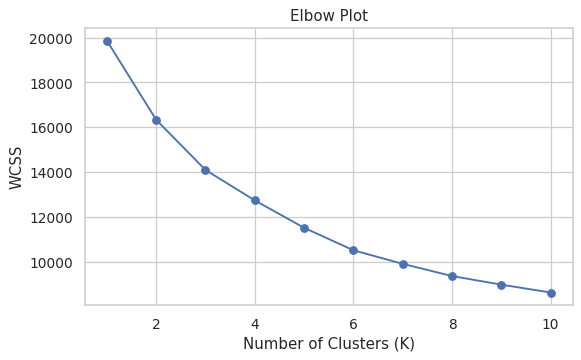

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss, "o-")
plt.xlabel("Number of Clusters (K)"); plt.ylabel("WCSS"); plt.title("Elbow Plot")
plt.show()

**Q12.** K-Means based on the elbow recommendation.

In [ ]:
elbow_k = 3
kmeans_elbow = KMeans(n_clusters=elbow_k, n_init=25, random_state=123).fit(scaled_data)

print("Cluster assignments:", kmeans_elbow.labels_)
display(pd.DataFrame(kmeans_elbow.cluster_centers_, columns=scaled_data.columns, index=range(1, elbow_k + 1)))
print(pd.Series(kmeans_elbow.labels_).value_counts().sort_index())

Cluster assignments: [0 2 1 ... 0 2 2]


,kids,age,education,year,siblings,agefirstbirth
1,-0.289189,-0.702969,-0.180601,0.021849,0.023095,-0.536754
2,-0.393735,0.035377,0.838538,-0.000841,-0.309558,1.037020
3,0.912791,1.047533,-0.709775,-0.032863,0.329547,-0.392143


0    1375
1    1048
2     889
Name: count, dtype: int64


## PART B: Hierarchical Clustering

**Q1.** Prepare the numeric data.

In [ ]:
hierarchical_data = (data.select_dtypes(include="number")
                     .drop(columns=["rownames", "KMeans_Cluster"], errors="ignore").dropna())

**Q2.** View the dataset.

In [ ]:
display(hierarchical_data.head())
hierarchical_data.info()

,kids,age,education,year,siblings,agefirstbirth
1,1,30,13,2002,4,19.0
2,1,55,2,2002,1,27.0
3,2,57,16,2002,1,22.0
4,2,71,12,2002,6,29.0
8,1,35,12,2002,0,21.0


<class 'pandas.DataFrame'>
Index: 3312 entries, 1 to 9118
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   kids           3312 non-null   int64  
 1   age            3312 non-null   int64  
 2   education      3312 non-null   int64  
 3   year           3312 non-null   int64  
 4   siblings       3312 non-null   int64  
 5   agefirstbirth  3312 non-null   float64
dtypes: float64(1), int64(5)
memory usage: 181.1 KB


**Q3.** Check missing values.

In [ ]:
hierarchical_data.isna().sum()

kids             0
age              0
education        0
year             0
siblings         0
agefirstbirth    0
dtype: int64

**Q4.** Select only numerical attributes.

In [ ]:
hierarchical_data = hierarchical_data.select_dtypes(include="number")
hierarchical_data.head()

,kids,age,education,year,siblings,agefirstbirth
1,1,30,13,2002,4,19.0
2,1,55,2,2002,1,27.0
3,2,57,16,2002,1,22.0
4,2,71,12,2002,6,29.0
8,1,35,12,2002,0,21.0


**Q5.** Standardize the data.

In [ ]:
scaled_hierarchical = scale(hierarchical_data)
scaled_hierarchical.head()

,kids,age,education,year,siblings,agefirstbirth
1,-1.079839,-1.124489,0.036898,1.179615,-0.018862,-0.747185
2,-1.079839,0.361501,-3.882231,1.179615,-0.907054,0.899170
3,-0.385117,0.480380,1.105751,1.179615,-0.907054,-0.129802
4,-0.385117,1.312534,-0.319387,1.179615,0.573266,1.310758
8,-1.079839,-0.827291,-0.319387,1.179615,-1.203118,-0.335596


**Q6–Q7.** Euclidean distance and hierarchical clustering using Ward's method.

In [ ]:
# Ward linkage on Euclidean distances (equivalent to R's dist() + hclust(method = "ward.D2"))
hierarchical_model = linkage(scaled_hierarchical.values, method="ward", metric="euclidean")

**Q8.** Dendrogram.

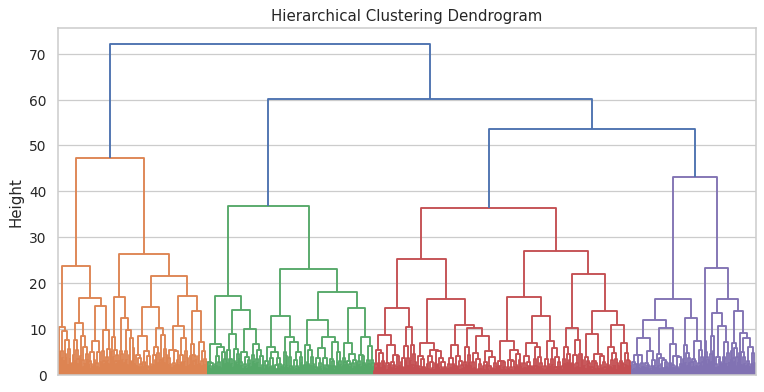

In [ ]:
plt.figure(figsize=(10, 5))
dendrogram(hierarchical_model, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram")
plt.ylabel("Height")
plt.show()

**Q9.** Divide into 3 clusters and display assignments.

In [ ]:
hierarchical_clusters = fcluster(hierarchical_model, t=3, criterion="maxclust")
hierarchical_clusters

array([3, 1, 3, ..., 3, 1, 1], shape=(3312,), dtype=int32)

**Q10.** Number of samples in each cluster.

In [ ]:
pd.Series(hierarchical_clusters).value_counts().sort_index()

1     709
2     791
3    1812
Name: count, dtype: int64

---
# ASSESSMENT IX — Principal Component Analysis

**Q1.** Load the dataset and the required libraries.

In [ ]:
from sklearn.decomposition import PCA

data = pd.read_excel(data_path)

**Q2.** Number of rows and columns.

In [ ]:
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

Number of rows: 9120
Number of columns: 11


**Q3.** Extract numeric columns, clean, and normalize into `data_scaled`.

In [ ]:
numeric_data = data.select_dtypes(include="number").dropna()
numeric_data = numeric_data.loc[:, numeric_data.std(ddof=1) > 0]
data_scaled = scale(numeric_data)
data_scaled.head()

,rownames,kids,age,education,year,siblings,agefirstbirth
1,-1.553644,-1.079839,-1.124489,0.036898,1.179615,-0.018862,-0.747185
2,-1.553346,-1.079839,0.361501,-3.882231,1.179615,-0.907054,0.899170
3,-1.553049,-0.385117,0.480380,1.105751,1.179615,-0.907054,-0.129802
4,-1.552751,-0.385117,1.312534,-0.319387,1.179615,0.573266,1.310758
8,-1.551560,-1.079839,-0.827291,-0.319387,1.179615,-1.203118,-0.335596


**Q4.** PCA on `data_scaled` with summary.

In [ ]:
pca = PCA().fit(data_scaled)
pc_names = [f"PC{i}" for i in range(1, len(pca.explained_variance_) + 1)]
pca_summary = pd.DataFrame({
    "Standard deviation": np.sqrt(pca.explained_variance_),
    "Proportion of Variance": pca.explained_variance_ratio_,
    "Cumulative Proportion": np.cumsum(pca.explained_variance_ratio_),
}, index=pc_names).T
print("Importance of components:")
print(pca_summary.round(5))

Importance of components:
                            PC1      PC2      PC3      PC4      PC5      PC6  \
Standard deviation      1.35341  1.30199  1.06924  0.95969  0.83458  0.67463   
Proportion of Variance  0.26168  0.24217  0.16332  0.13157  0.09950  0.06502   
Cumulative Proportion   0.26168  0.50384  0.66717  0.79874  0.89824  0.96326   

                            PC7  
Standard deviation      0.50712  
Proportion of Variance  0.03674  
Cumulative Proportion   1.00000  


**Q5.** Scree plot (percentage of variance with data labels, y-axis 0–60).

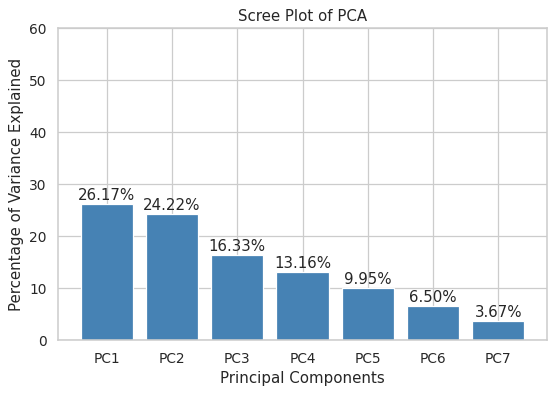

In [ ]:
variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(7, 4.5))
bars = plt.bar(pc_names, variance, color="steelblue")
for b, v in zip(bars, variance):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.2f}%", ha="center")
plt.ylim(0, 60)
plt.title("Scree Plot of PCA"); plt.xlabel("Principal Components"); plt.ylabel("Percentage of Variance Explained")
plt.show()

**Q6.** PCA biplot.

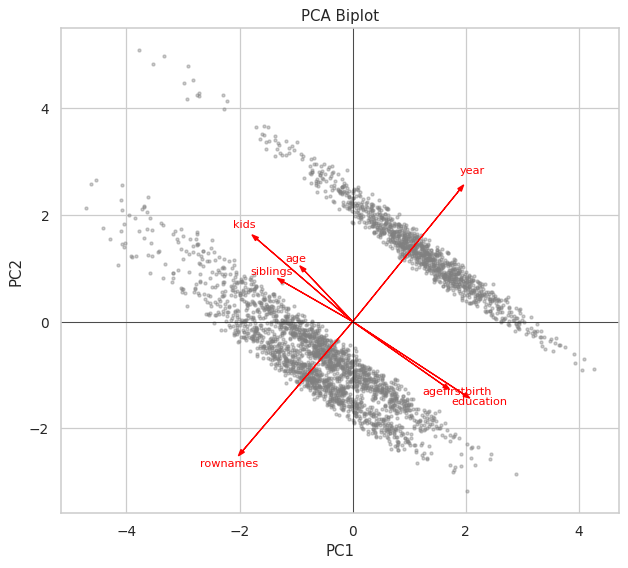

In [ ]:
scores = pca.transform(data_scaled)
loadings = pca.components_.T                       # variables x components
arrow_scale = np.abs(scores[:, :2]).max() * 0.9

plt.figure(figsize=(8, 7))
plt.scatter(scores[:, 0], scores[:, 1], s=6, alpha=0.4, color="gray")
for i, var in enumerate(data_scaled.columns):
    plt.arrow(0, 0, loadings[i, 0] * arrow_scale, loadings[i, 1] * arrow_scale,
              color="red", head_width=0.08, length_includes_head=True)
    plt.text(loadings[i, 0] * arrow_scale * 1.08, loadings[i, 1] * arrow_scale * 1.08, var,
             color="red", ha="center", fontsize=9)
plt.axhline(0, color="black", linewidth=0.5); plt.axvline(0, color="black", linewidth=0.5)
plt.title("PCA Biplot"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

**Q7.** Extract PCA scores into `pca_scores` and display the first six rows.

In [ ]:
pca_scores = pd.DataFrame(scores, columns=pc_names)
print(pca_scores.head(6))

        PC1       PC2       PC3       PC4       PC5       PC6       PC7
0  1.583090  1.065620 -1.690550 -0.016013 -0.297347 -0.362420 -0.275920
1  0.381501  2.017572 -0.230944  0.238273 -3.868791  1.575414 -0.168410
2  1.957282  1.015137  0.405182 -0.690719  0.130109 -0.807500 -0.270380
3  1.251032  1.512881  1.255485  1.318086 -0.767438  0.016769 -0.256114
4  1.858750  0.919953 -1.101446 -0.822202 -1.032204  0.026404 -0.234119
5  0.960852  1.740434 -0.111671 -0.990738 -0.341411  0.035972 -0.250392


**Q8.** Scatter plot of PC1 vs PC2 (blue circular points, registration number in title).

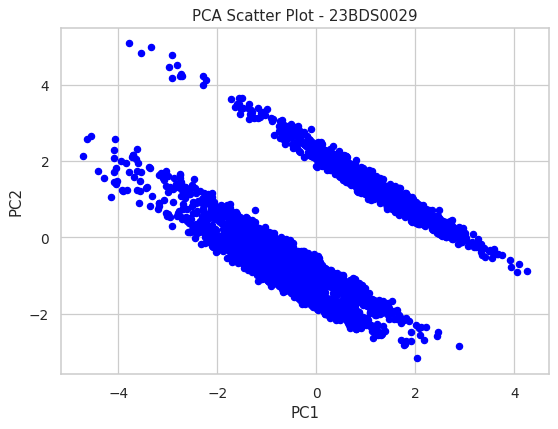

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", s=25)
plt.title("PCA Scatter Plot - 23BDS0029")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()